# Cargar Datos

In [1]:
import pandas as pd
from sklearn.preprocessing import PowerTransformer
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
from matplotlib.lines import Line2D 

In [2]:
#ruta='../data/processed/df_max.xlsx'
ruta='../data/processed/df_mean.xlsx'
intact=pd.read_excel(ruta)
intact.head(10)

,origin_db,subject,stimulus,Channel 1_VAR_STD,Channel 2_VAR_STD,Channel 3_VAR_STD,Channel 4_VAR_STD,Channel 5_VAR_STD,Channel 6_VAR_STD,Channel 7_VAR_STD,...,Channel 7_MNF,Channel 8_MNF,Channel 1_SSC,Channel 2_SSC,Channel 3_SSC,Channel 4_SSC,Channel 5_SSC,Channel 6_SSC,Channel 7_SSC,Channel 8_SSC
0,NinaProDB1,1,0,28.991368,12.935956,43.790300,8.455451,0.710315,0.877439,60.235039,...,34189.809891,16623.688090,10883.333333,1096.000000,5070.083333,1970.000000,4216.083333,911.583333,13913.083333,20087.750000
1,NinaProDB1,1,22,0.608646,1.797925,1.788122,0.217035,0.014690,0.050668,1.775730,...,121.928070,86.762268,73.775000,58.391667,85.508333,40.250000,44.066667,49.408333,88.775000,90.408333
2,NinaProDB1,1,25,0.731750,0.609576,1.010855,0.320152,0.016626,0.026118,5.284745,...,116.433601,81.825697,67.208333,46.700000,67.775000,60.733333,34.958333,34.900000,95.450000,100.016667
3,NinaProDB1,1,27,1.990391,0.936693,1.440167,0.092730,0.014959,0.124602,2.443427,...,119.168814,78.168460,90.391667,68.083333,72.508333,41.483333,41.900000,49.358333,96.100000,100.675000
4,NinaProDB1,1,30,5.515111,5.975873,3.904813,0.514608,0.036709,0.035766,4.499380,...,113.145069,82.191062,84.983333,57.891667,66.583333,35.475000,50.291667,51.191667,99.508333,99.050000
5,NinaProDB1,1,31,0.052204,0.264928,1.153939,0.027451,0.028336,0.004607,0.267303,...,98.924799,79.864296,60.583333,40.091667,63.250000,22.316667,55.875000,31.891667,90.600000,104.325000
6,NinaProDB1,1,37,1.487167,2.997959,2.633301,0.138350,0.016632,0.026465,3.920891,...,92.682723,62.861022,102.916667,86.533333,97.975000,50.983333,41.008333,49.116667,116.125000,109.133333
7,NinaProDB1,1,40,0.942206,1.371640,0.361698,0.052621,0.045568,0.014923,3.239635,...,106.482256,78.299362,101.083333,88.200000,59.733333,31.275000,59.750000,42.983333,102.725000,123.400000
8,NinaProDB1,2,0,179.530483,245.780416,17.554612,5.215483,4.685449,0.211683,3.785810,...,27811.712953,26581.439480,24984.916667,26526.916667,16932.416667,1668.583333,4446.666667,739.583333,4595.916667,17078.833333
9,NinaProDB1,2,22,1.946780,2.254924,0.780461,1.080688,0.131727,0.012522,0.422335,...,130.392994,94.059982,109.800000,101.441667,82.283333,64.333333,45.350000,27.766667,61.483333,101.008333


In [3]:
features = ['VAR_STD', 'Range', 'Energy', 'Peak_to_Peak', 'VAR', 'Max', 'MNF', 'SSC']
signal_cols = [f'Channel {ch}_{feat}' for ch in range(1, 9) for feat in features]

# Normalización [subject, origin_db]

In [4]:
def normalize_by_subject_only(df, signal_cols):
    """
    Aplica Z-score por (subject, origin_db).

    Casos especiales:
    - Menos de 2 muestras -> se asigna 0.
    - STD = 0 (señal constante) -> se asigna 1 para evitar divisiones por cero.
    - STD = NaN -> se asigna 1 para evitar propagar NaN.
    """

    # Copia para no modificar el DataFrame original
    df_res = df.copy()

    # Agrupar por sujeto y base de datos
    for (subj, db), group in df.groupby(["subject", "origin_db"]):
        idx = group.index

        # Extraer señales y convertir a float
        sub_data = df_res.loc[idx, signal_cols].values.astype(float)

        # Si hay menos de 2 muestras no es posible calcular una desviación estándar muestral fiable
        if sub_data.shape[0] < 2:
            df_res.loc[idx, signal_cols] = 0.0
            continue

        # Media y STD ignorando NaN
        means = np.nanmean(sub_data, axis=0)
        stds = np.nanstd(sub_data, axis=0, ddof=1)

        # Detectar STD problemáticas: señal constante (std=0) o std NaN por falta de muestras válidas
        invalid_std = (stds == 0) | np.isnan(stds)

        # Sustituir por 1 para evitar divisiones problemáticas
        stds[invalid_std] = 1.0

        # Aplicar Z-score
        normalized = (sub_data - means) / stds

        # Si una columna era todo NaN, la normalización sigue produciendo NaN; los convertimos a 0 para mantener estabilidad
        normalized = np.nan_to_num(normalized, nan=0.0, posinf=0.0, neginf=0.0)

        # Guardar resultados
        df_res.loc[idx, signal_cols] = normalized

    return df_res

intact_norm = normalize_by_subject_only(intact, signal_cols)
intact_norm.to_csv("../data/processed/intact_norm.csv", index=False)

In [5]:
def validate_normalization(df_normalized, signal_cols):

    problems = []

    # Revisar cada sujeto dentro de cada base de datos
    for (subj, db), group in df_normalized.groupby(
            ["subject", "origin_db"]):

        # Estadísticos tras la normalización
        means = group[signal_cols].mean()
        stds = group[signal_cols].std(ddof=1)

        # Guardar resultados por señal
        for col in signal_cols:

            problems.append({
                "subject": subj,
                "db": db,
                "signal": col,
                "mean_after": means[col],
                "std_after": stds[col]
            })

    return pd.DataFrame(problems)

validation = validate_normalization(intact_norm, signal_cols)
# Nan antes y después
print("NaN antes :", intact[signal_cols].isna().sum().sum())
print("NaN después:", intact_norm[signal_cols].isna().sum().sum())
# grupos cuya media no está cerca de 0
print(validation[validation["mean_after"].abs() > 0.01])
# grupos cuya std no está cerca de 1
print(validation[(validation["std_after"] - 1).abs() > 0.01])
print(validation["mean_after"].describe())
print(validation["std_after"].describe())

NaN antes : 0
NaN después: 0
Empty DataFrame
Columns: [subject, db, signal, mean_after, std_after]
Index: []
Empty DataFrame
Columns: [subject, db, signal, mean_after, std_after]
Index: []
count    5.568000e+03
mean     8.592614e-19
std      5.618834e-17
min     -2.914335e-16
25%     -2.775558e-17
50%      0.000000e+00
75%      2.775558e-17
max      2.914335e-16
Name: mean_after, dtype: float64
count    5.568000e+03
mean     1.000000e+00
std      8.878194e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: std_after, dtype: float64


Validación de lo anterior: 
- No hay ninguna señal con media lejos de 0.
- No hay ninguna señal con desviación estándar lejos de 1.
- La normalización por (subject, origin_db) parece estar funcionando correctamente

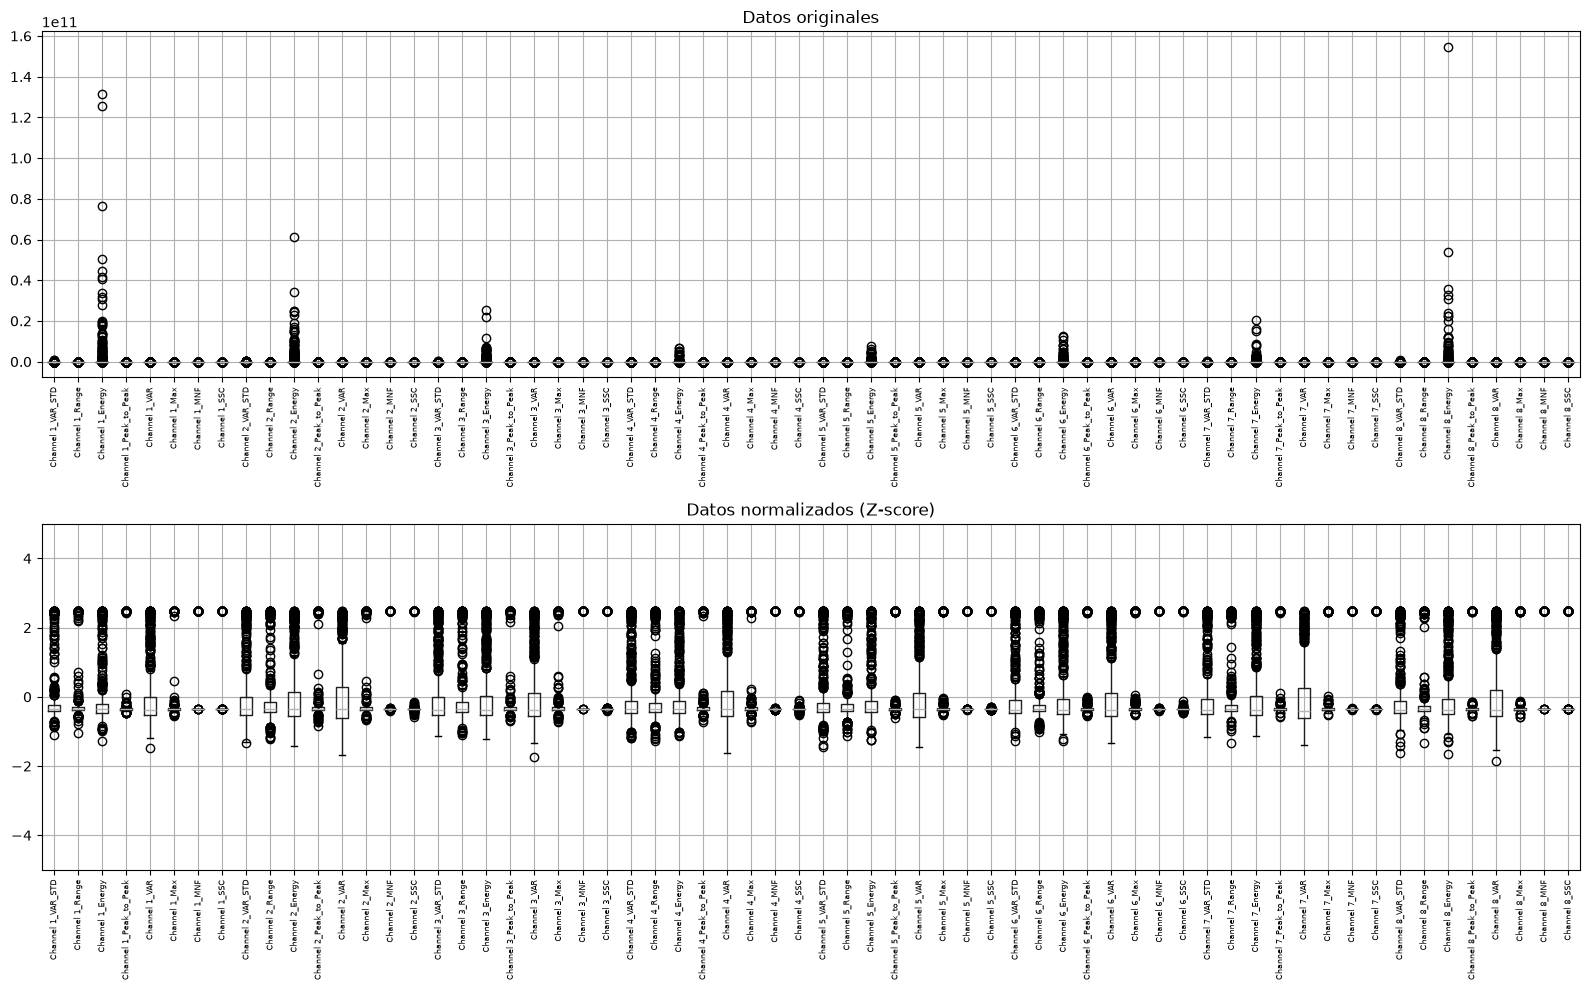

In [6]:
def plot_box_before_after(df_original, df_norm, signal_cols):
    fig, axes = plt.subplots(2, 1, figsize=(16, 10))
    df_original[signal_cols].boxplot(ax=axes[0], rot=90)
    axes[0].set_title("Datos originales")
    df_norm[signal_cols].boxplot(ax=axes[1], rot=90)
    axes[1].set_title("Datos normalizados (Z-score)")
    axes[1].set_ylim(-5, 5)
    for ax in axes:
        ax.tick_params(axis='x', labelsize=6)
    plt.tight_layout()
    plt.show()

plot_box_before_after(intact, intact_norm, signal_cols)

### Datos Originales normalizados

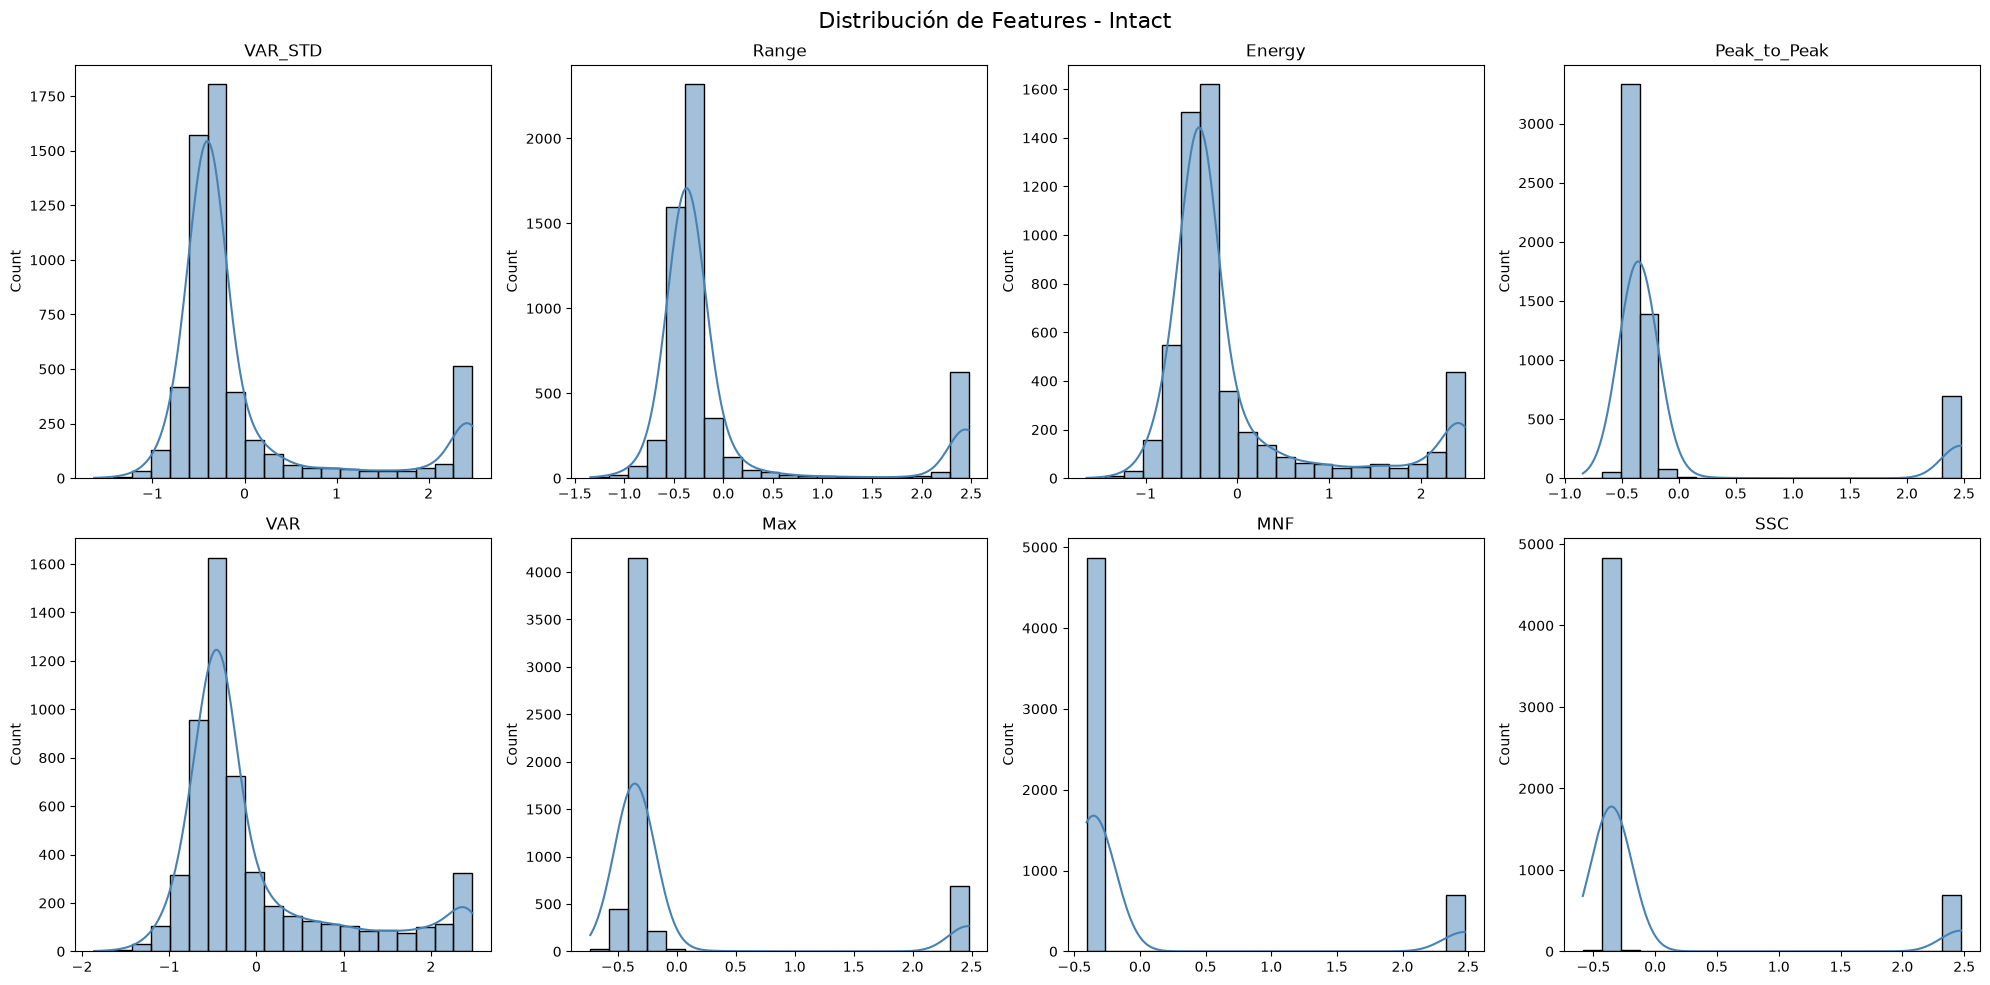

In [7]:
def plot_histograms_by_channel(df, title):
    features = ['VAR_STD', 'Range', 'Energy', 'Peak_to_Peak', 'VAR', 'Max', 'MNF', 'SSC']
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    fig.suptitle(title, fontsize=16)
    for i, feat in enumerate(features):
        ax = axes[i // 4][i % 4]
        vals = df[[f'Channel {ch}_{feat}' for ch in range(1, 9)]].values.flatten()
        sns.histplot(vals, kde=True, ax=ax, bins=20, color='steelblue')
        ax.set_title(feat, fontsize=12)
        ax.set_xlabel('')
    plt.tight_layout()
    plt.show()
    
plot_histograms_by_channel(intact_norm, 'Distribución de Features - Intact')

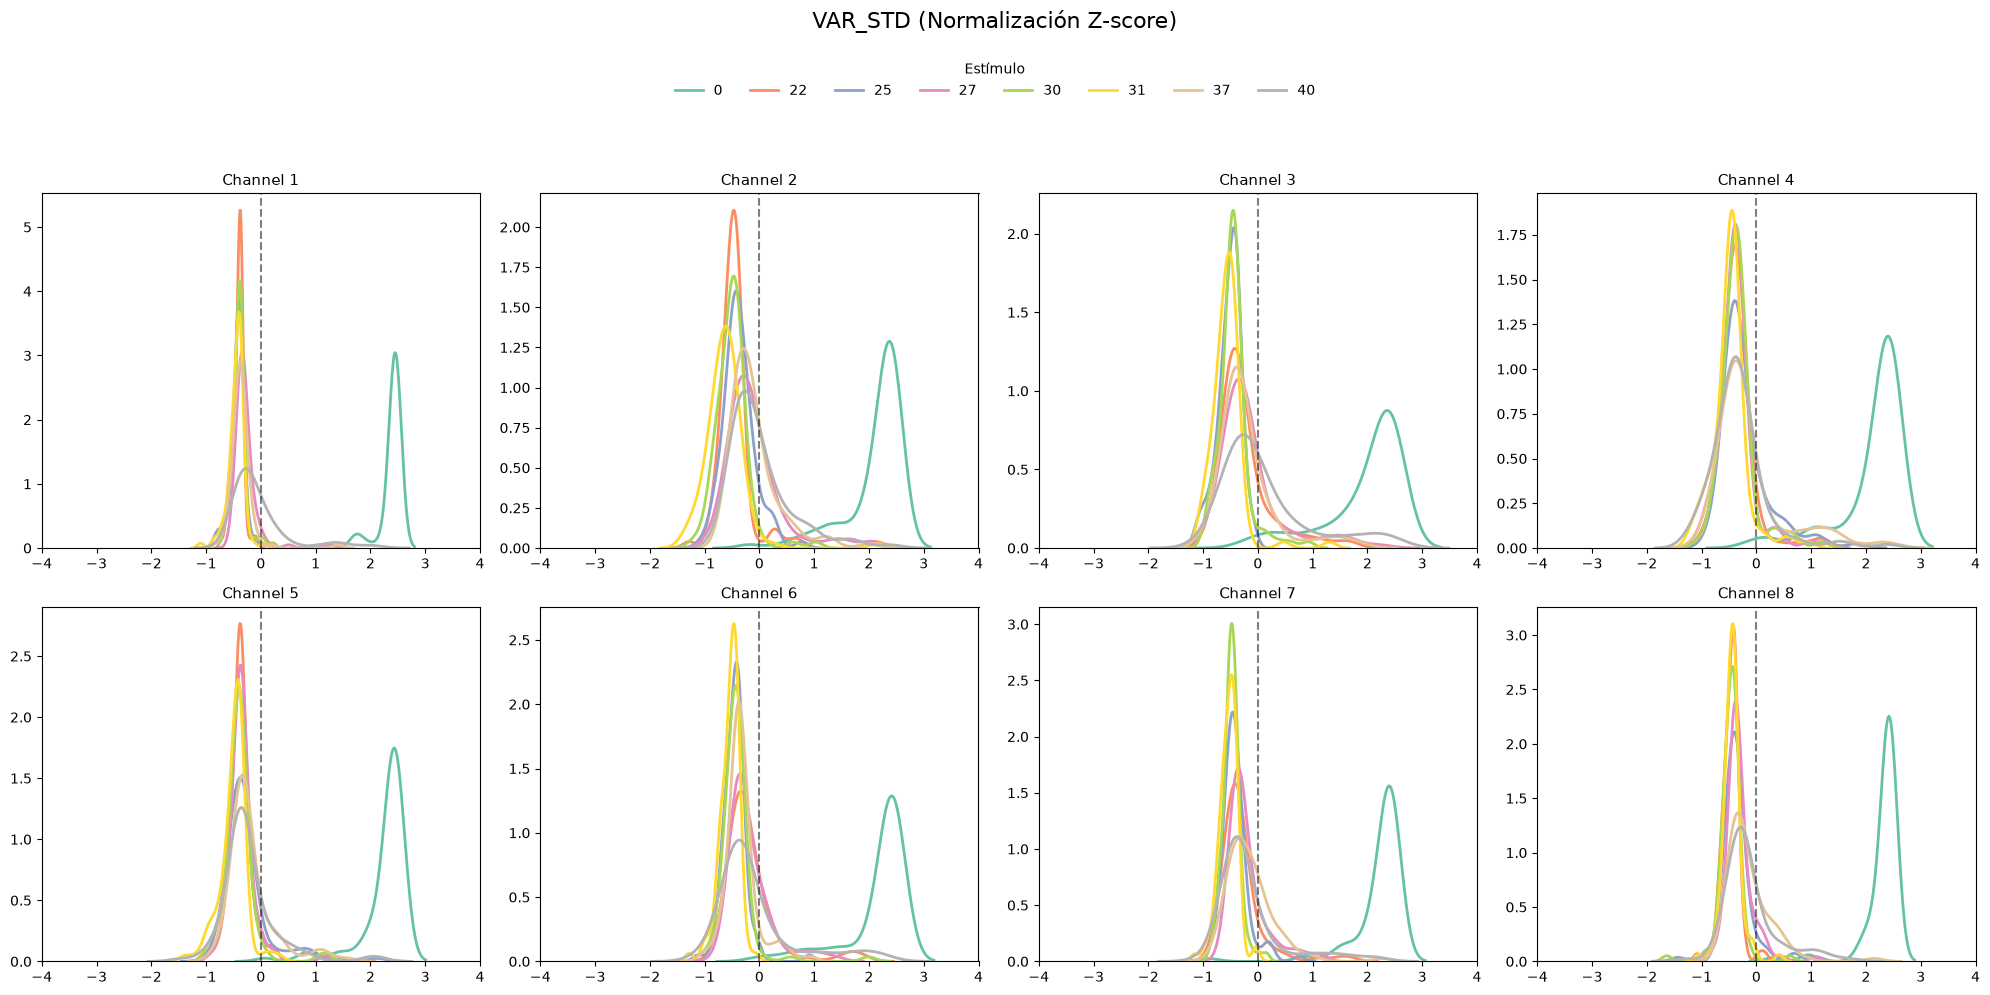

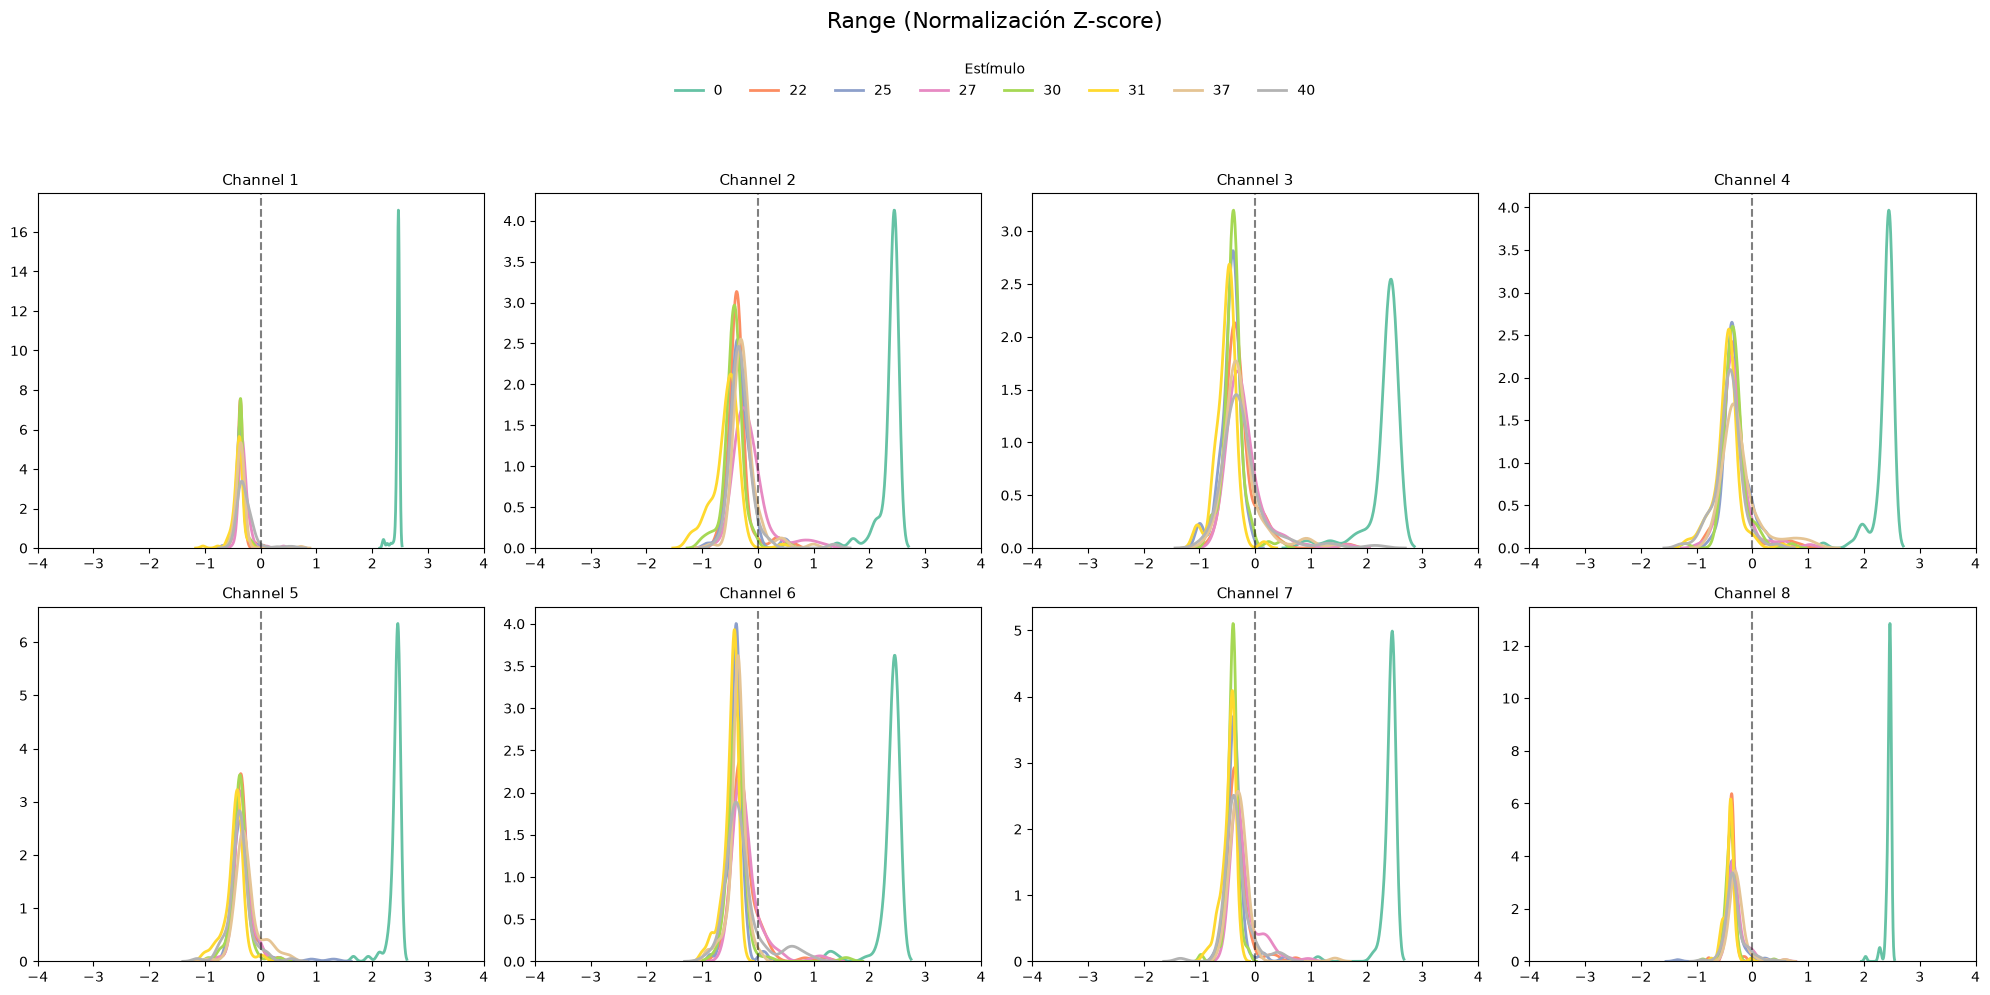

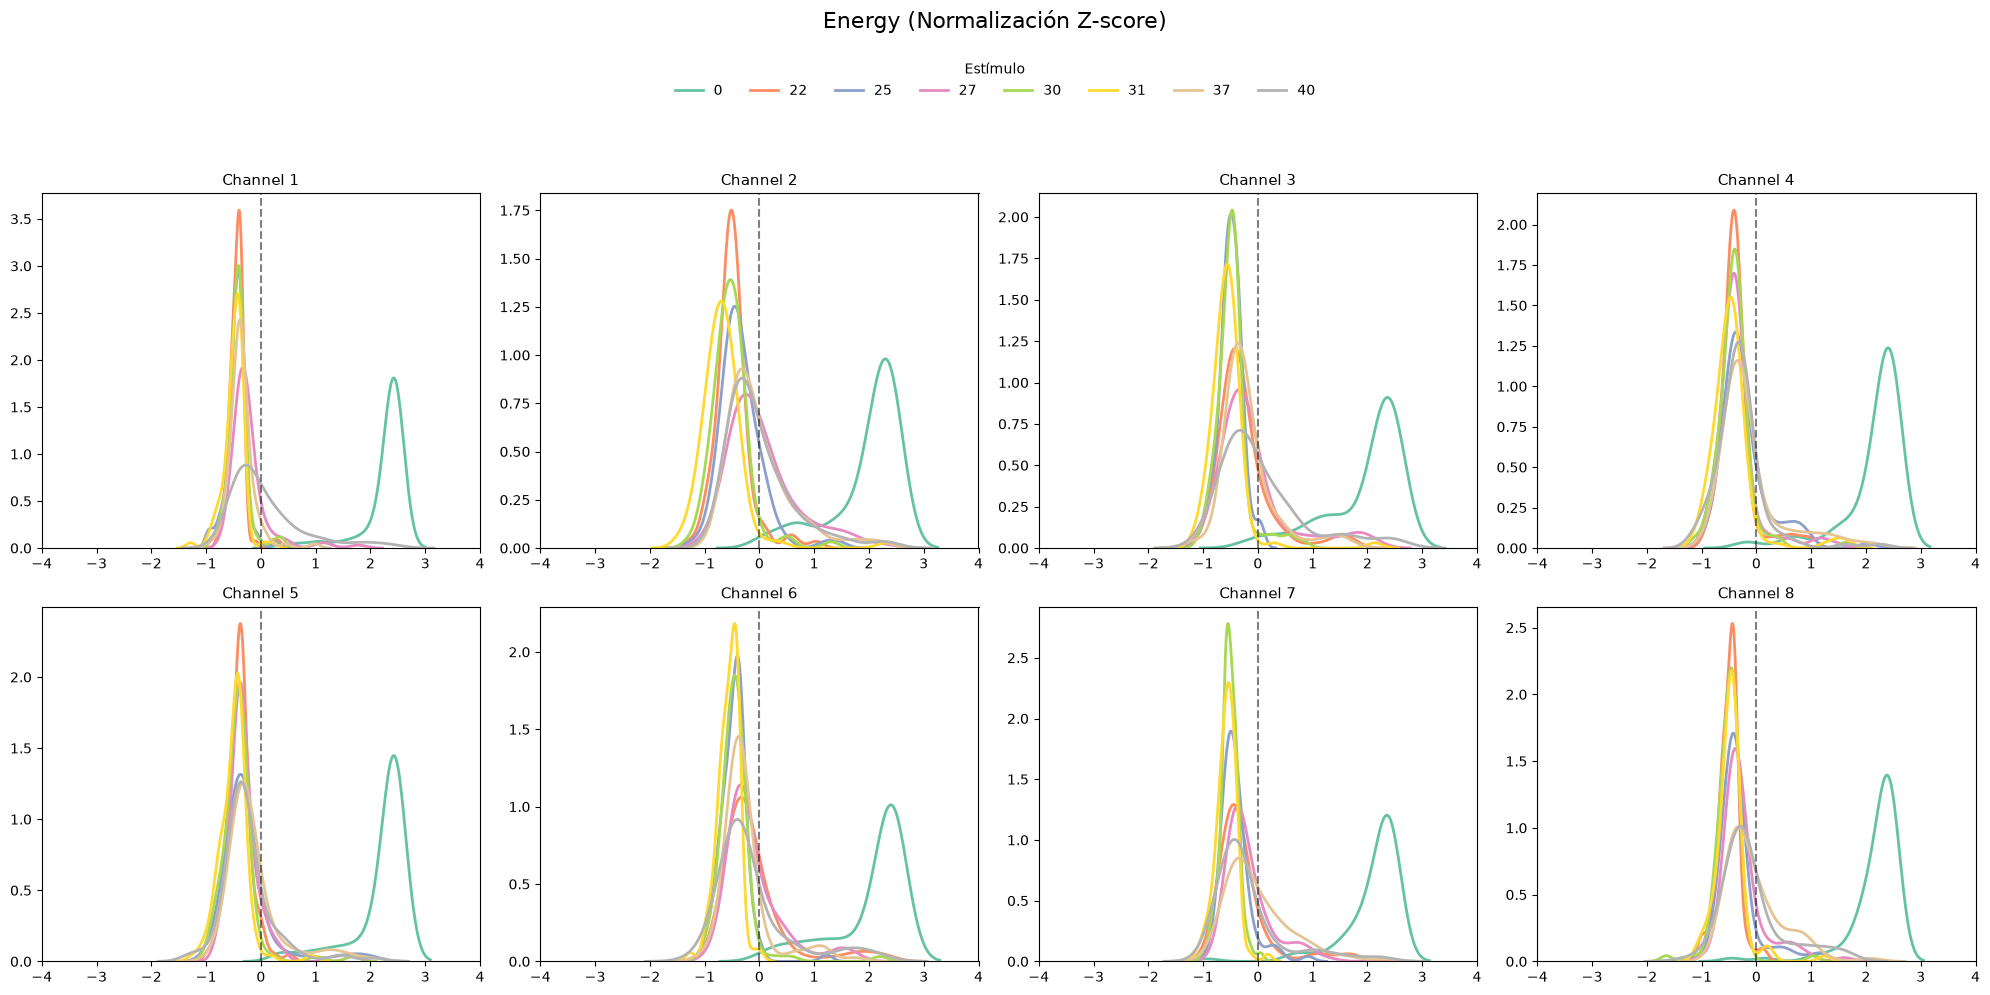

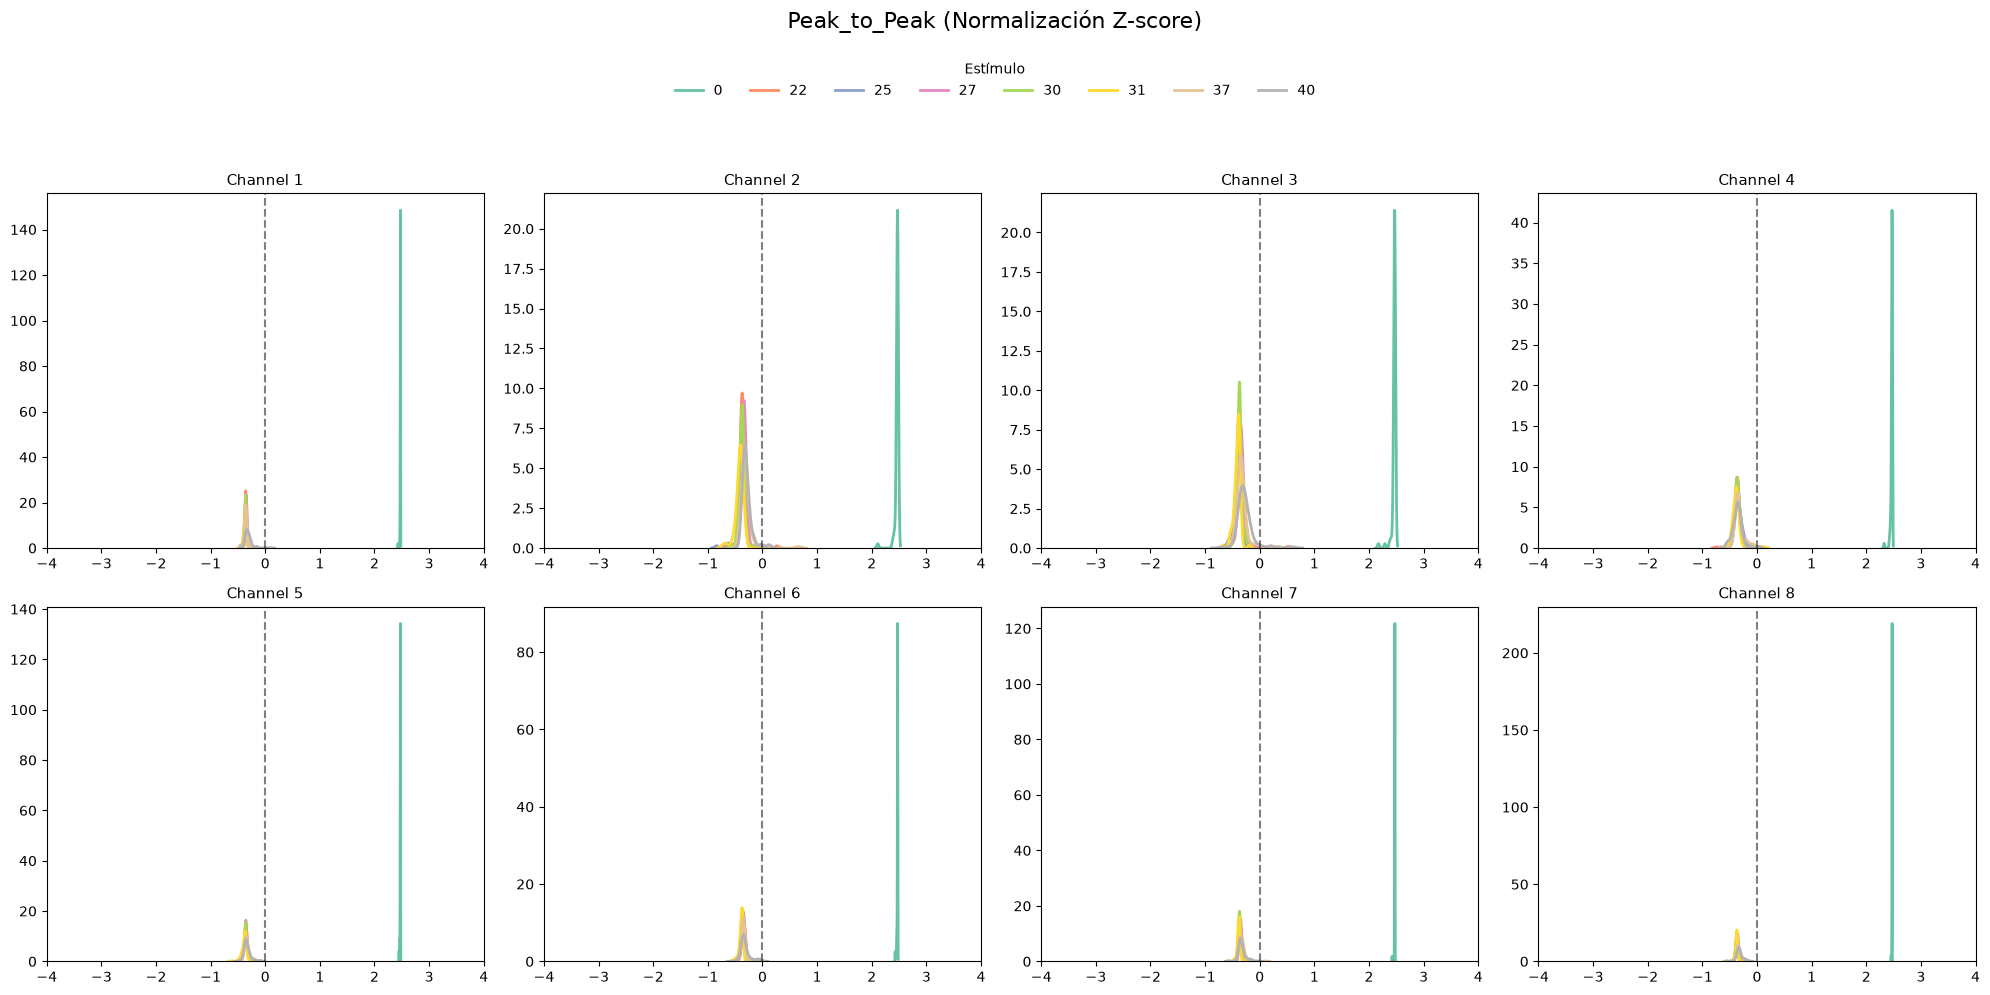

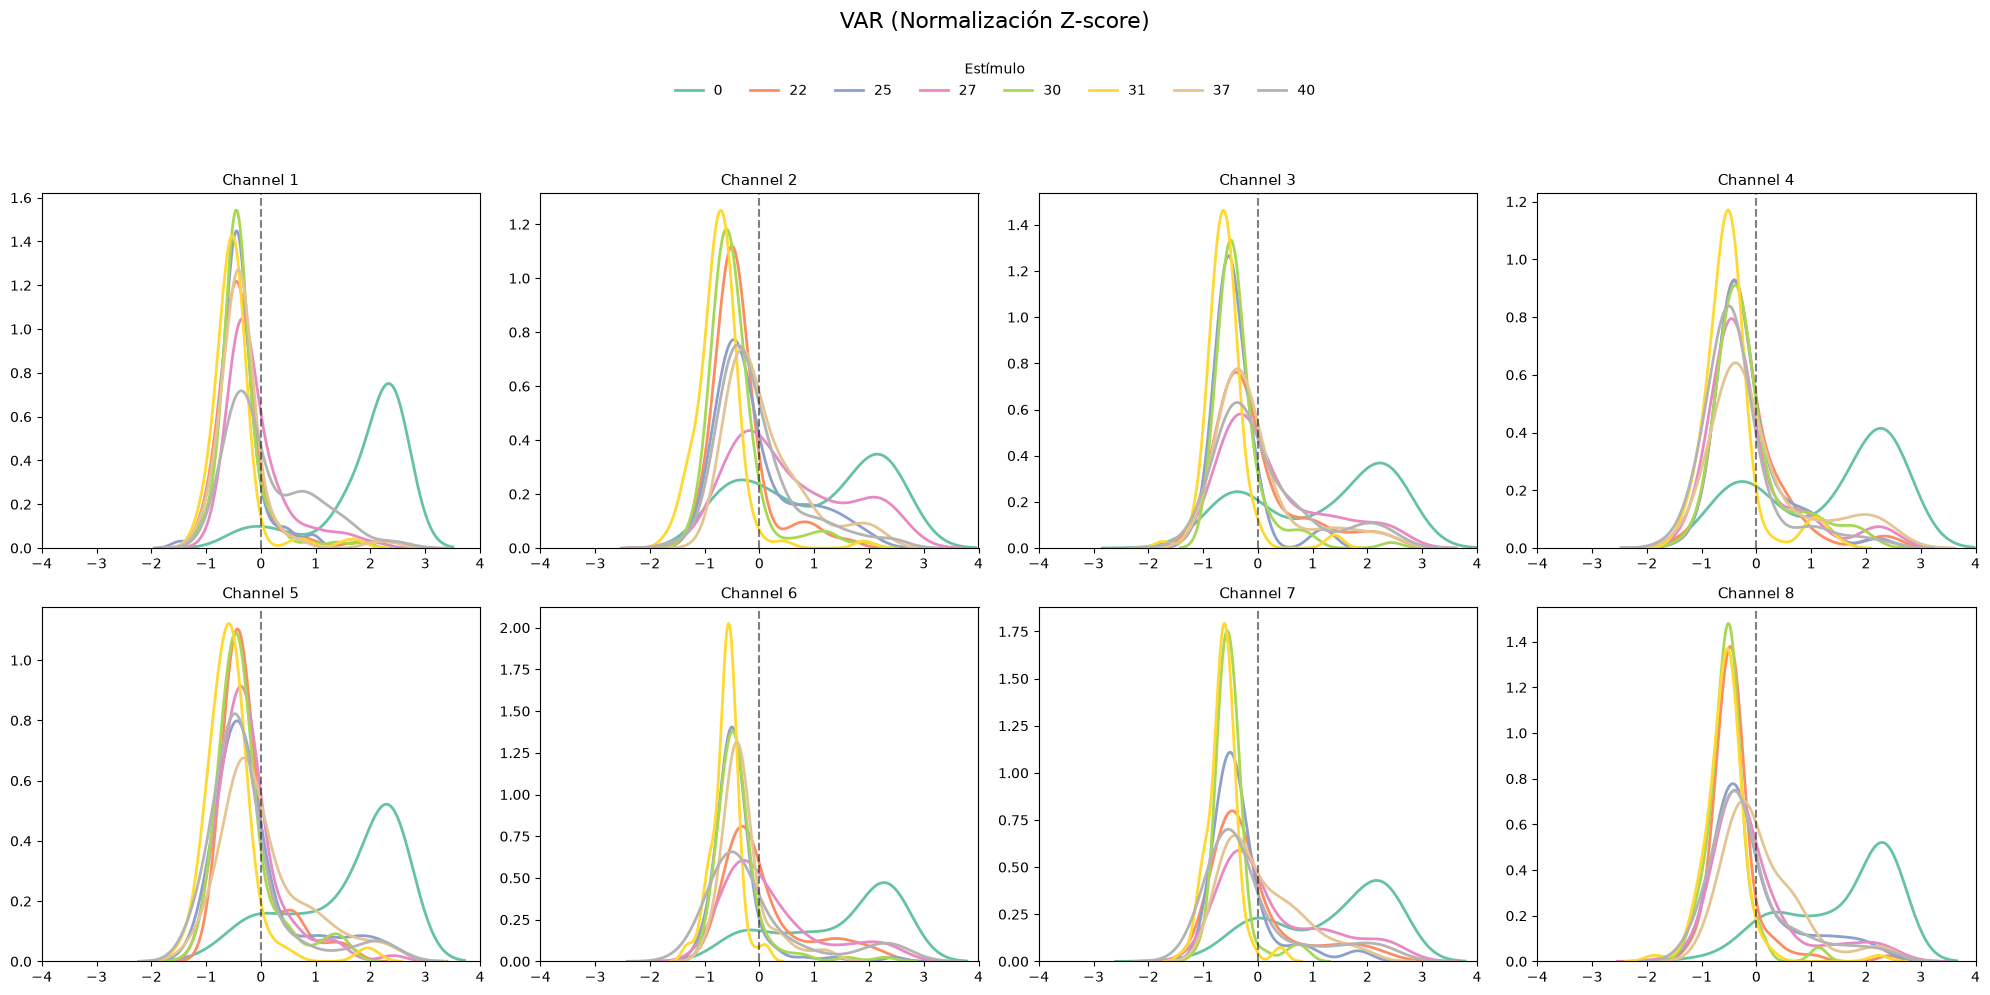

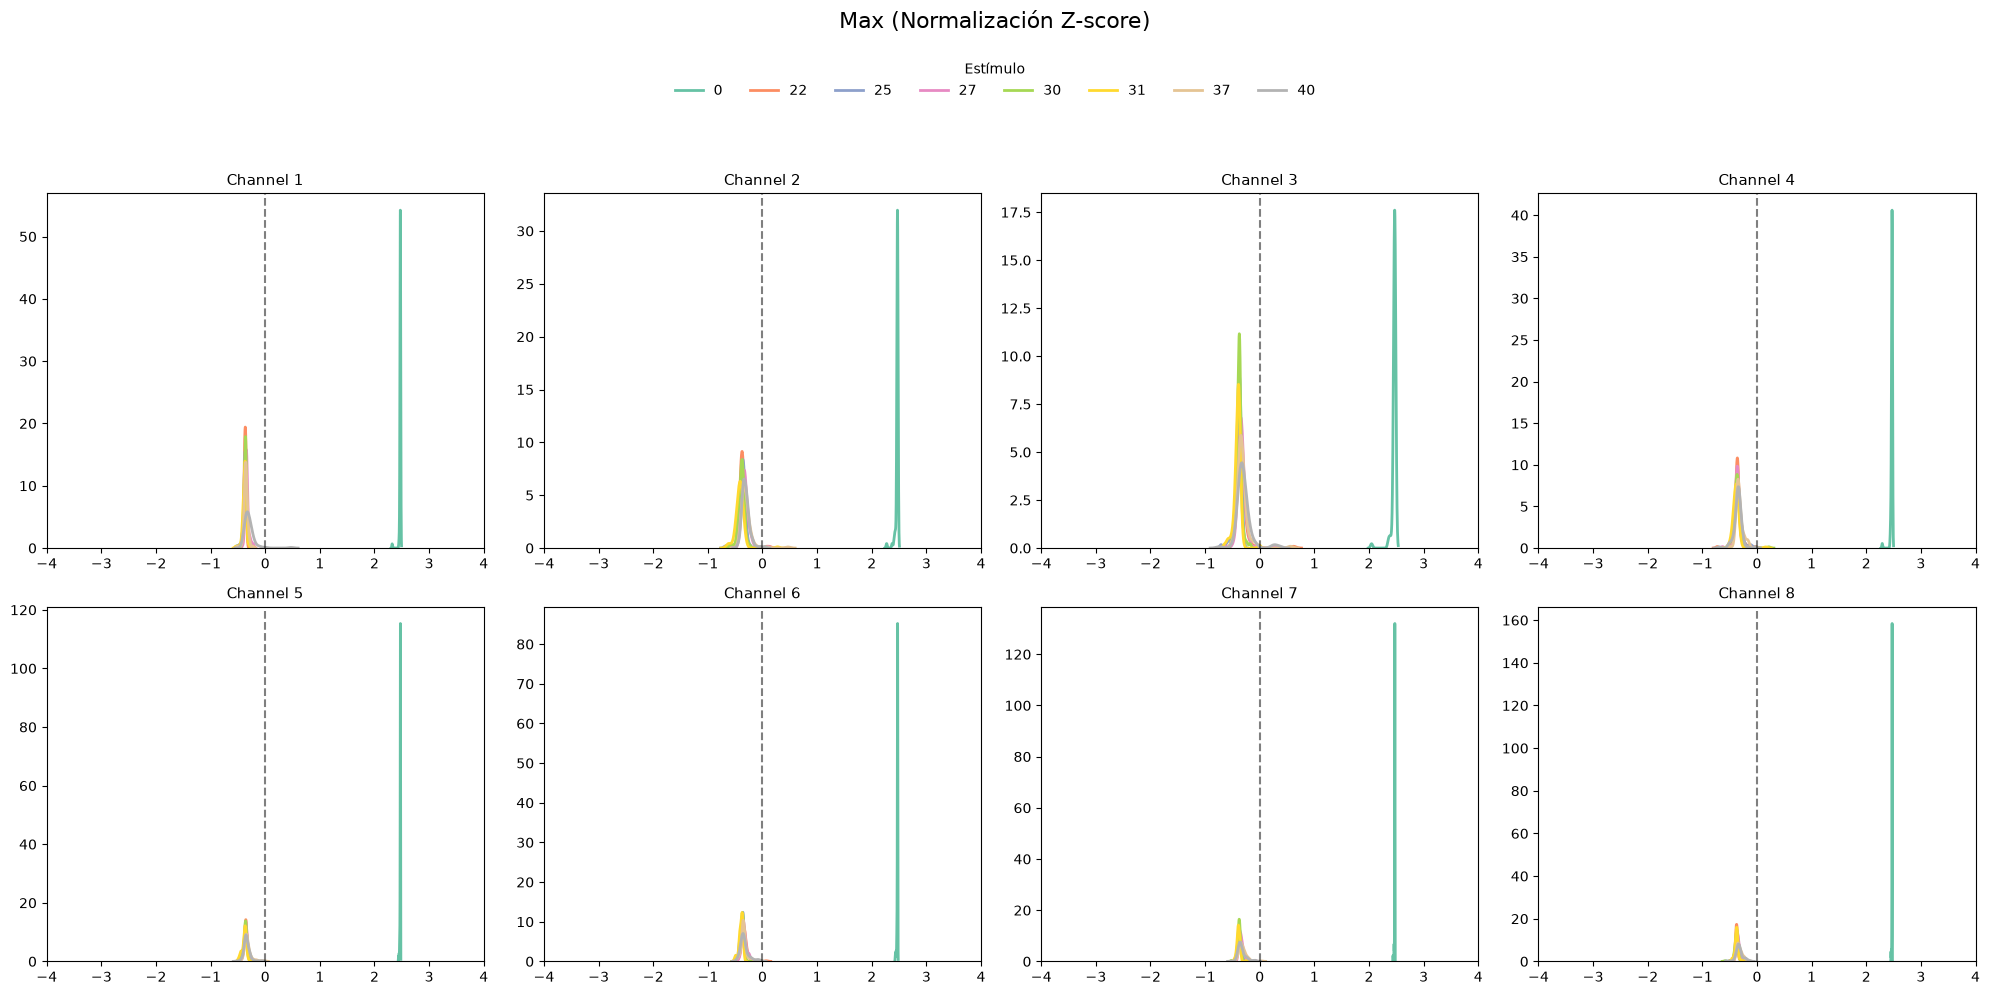

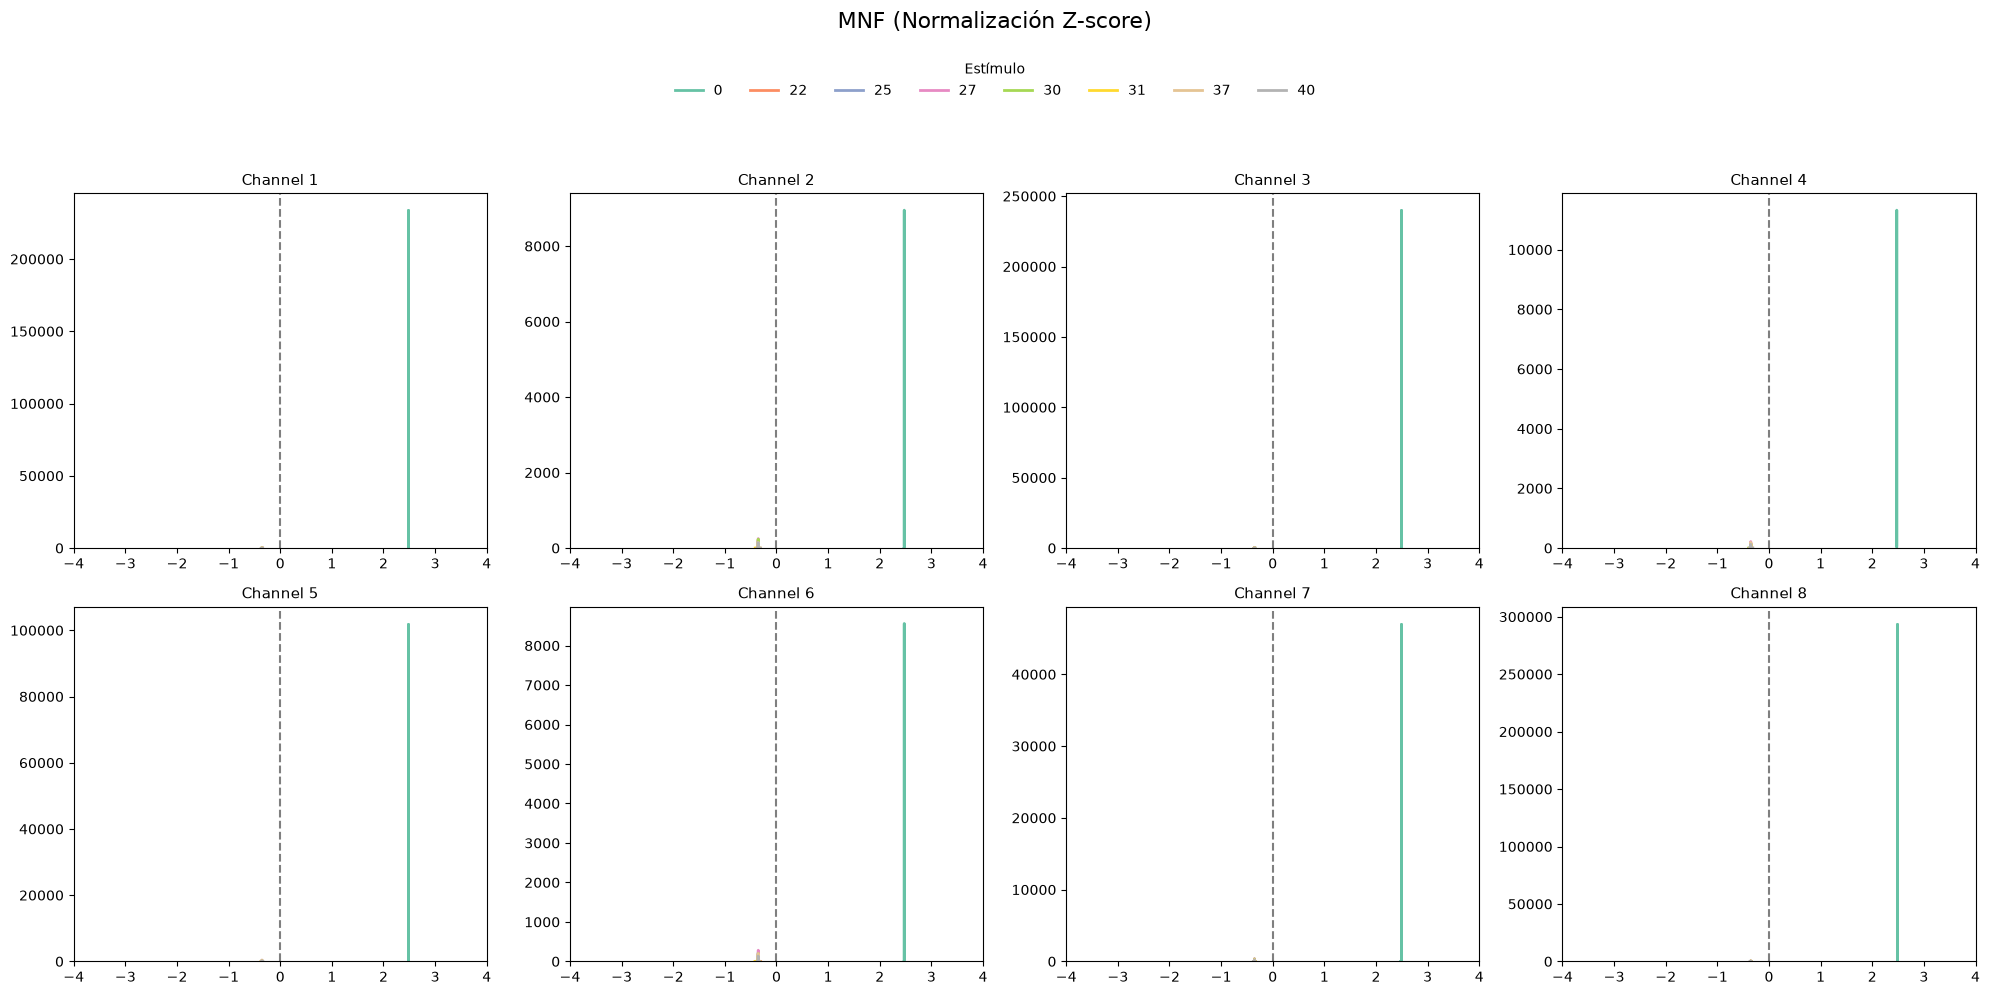

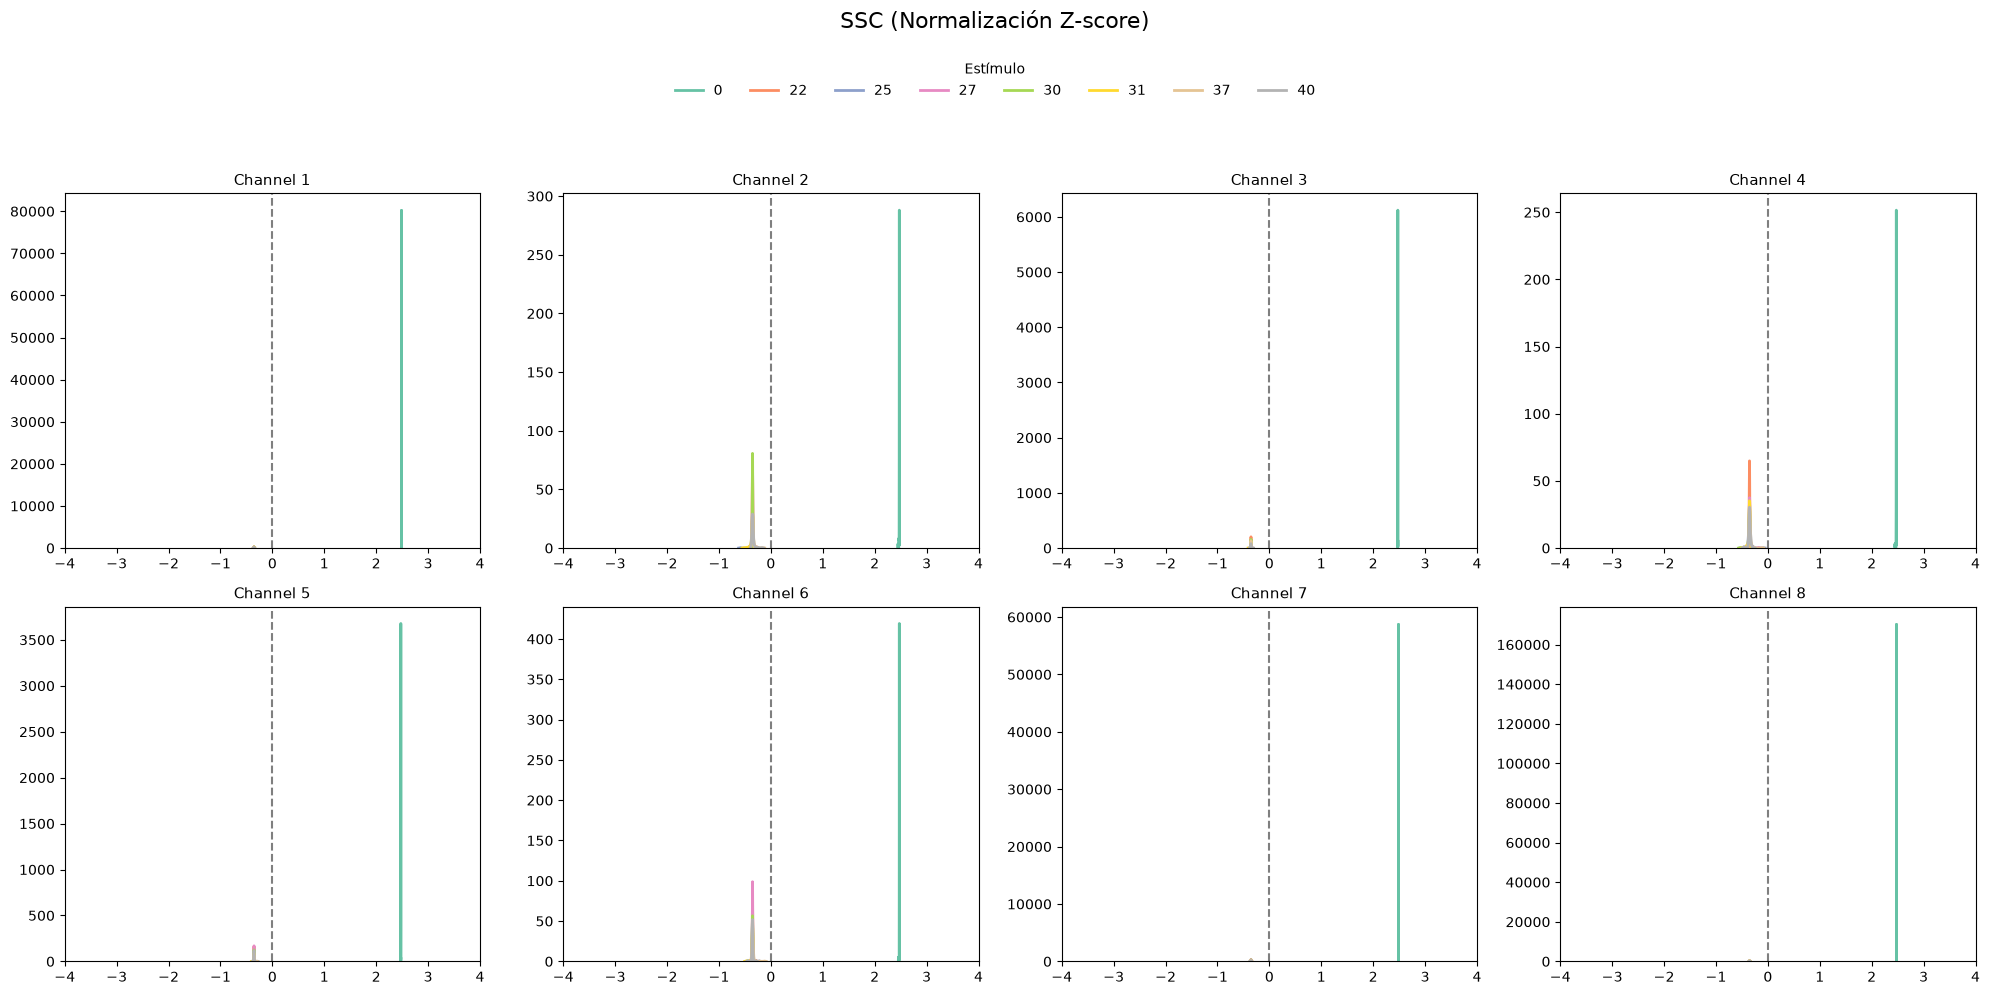

In [19]:
def plot_kde_normalized(df_norm, features):

    stimuli = sorted(df_norm['stimulus'].unique())
    colors = sns.color_palette('Set2' if len(stimuli) <= 8 else 'husl', len(stimuli))
    palette = dict(zip(stimuli, colors))

    for feature in features:

        fig, axes = plt.subplots(2, 4, figsize=(20, 10))

        for ch in range(1, 9):

            ax = axes[(ch - 1) // 4][(ch - 1) % 4]
            col = f'Channel {ch}_{feature}'

            for stim in stimuli:

                vals = df_norm.loc[df_norm['stimulus'] == stim, col]

                sns.kdeplot(
                    x=vals,
                    ax=ax,
                    color=palette[stim],
                    linewidth=2,
                    legend=False
                )

            ax.axvline(0, color='black', linestyle='--', alpha=0.5)

            # rango típico esperado para Z-score
            ax.set_xlim(-4, 4)

            ax.set_title(f'Channel {ch}', fontsize=11)
            ax.set_xlabel('')
            ax.set_ylabel('')

        handles = [Line2D([0], [0], color=palette[s], lw=2) for s in stimuli]

        fig.suptitle(f'{feature} (Normalización Z-score)', fontsize=16, y=0.99)

        fig.legend(
            handles,
            stimuli,
            title='Estímulo',
            loc='upper center',
            bbox_to_anchor=(0.5, 0.95),
            ncol=min(len(stimuli), 10),
            frameon=False
        )

        plt.tight_layout(rect=[0, 0, 1, 0.88])
        plt.show()

plot_kde_normalized(intact_norm, features)

### Histogramas

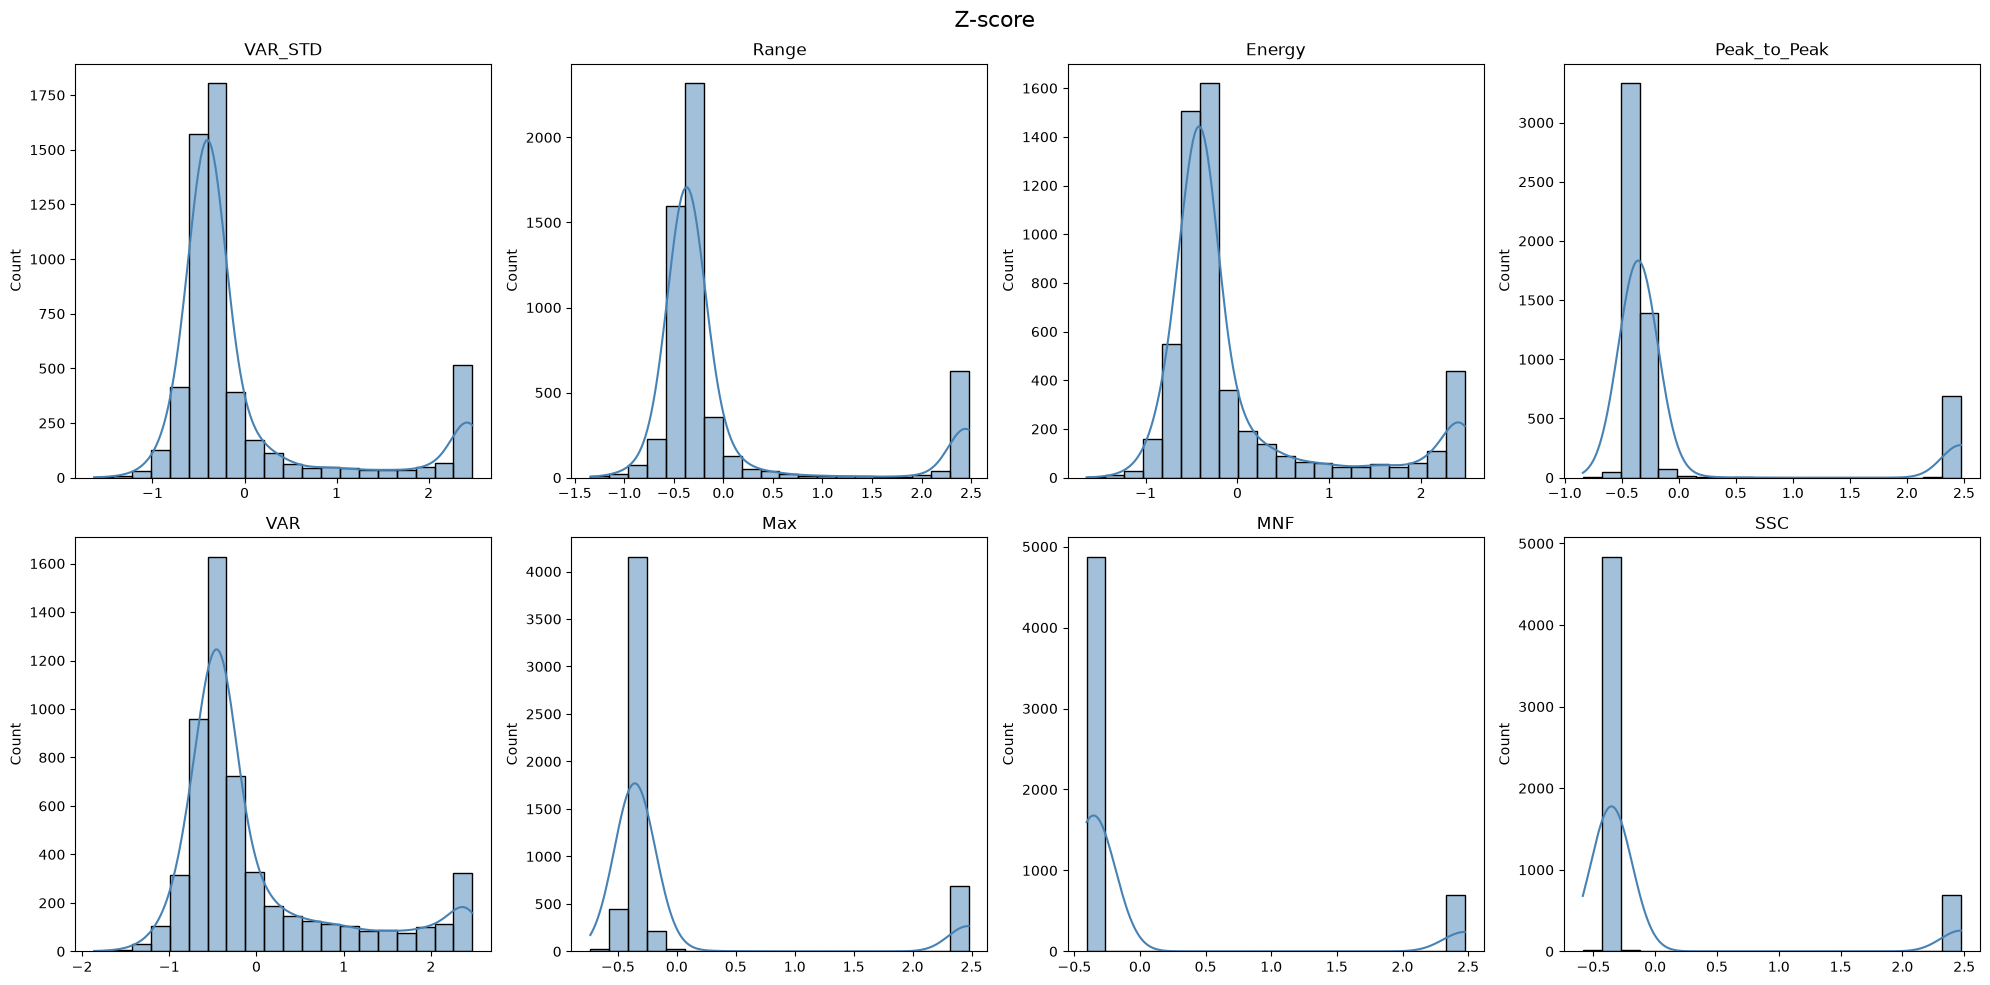

In [20]:
plot_histograms_by_channel(intact_norm,'Z-score')

>  Tenemos evidencia de una propiedad fisiológica real y no de un artefacto asociado al sujeto.
>
>  La separación entre reposo y estímulos se mantiene en aproximadamente el 90 % de las características.
>
>  La normalización preserva la diferencia entre reposo y estímulos, lo que indica que esta información no depende únicamente de las diferencias entre sujetos.
>
>  La normalización reduce las diferencias asociadas a los sujetos, permitiendo comparar las respuestas fisiológicas entre ellos.

# Transformación Yeo Johnson [subject, origin_db]

In [10]:
def yeo_johnson_by_subject(df, signal_cols):
    """
    Aplica Yeo-Johnson + Z-score por (subject, origin_db).

    La transformación se ajusta únicamente con los datos
    del sujeto dentro de cada base de datos.
    """

    # Copia para no modificar el DataFrame original
    df_res = df.copy()

    # Procesar cada sujeto dentro de cada DB por separado
    for (subj, db), group in df.groupby(['subject', 'origin_db']):

        # Índices del grupo actual
        idx = group.index

        # Extraer señales y asegurar formato numérico
        sub_data = df_res.loc[idx, signal_cols].values.astype(float)

        # Se requieren al menos dos muestras para estimar la transformación
        if sub_data.shape[0] < 2:
            continue

        try:
            # Yeo-Johnson permite valores positivos, negativos y cero
            # standardize=True aplica posteriormente un Z-score
            transformer = PowerTransformer(method='yeo-johnson',
                                           standardize=True)

            # Ajustar la transformación usando únicamente este sujeto
            # y reemplazar los valores originales por los transformados
            df_res.loc[idx, signal_cols] = transformer.fit_transform(sub_data)

        except Exception as e:
            # Reportar grupos problemáticos sin detener el procesamiento
            print(f'Error en {subj} - {db}: {e}')

    return df_res

intact_yj = yeo_johnson_by_subject(intact, signal_cols)
intact_yj.to_csv("../data/processed/intact_yj.csv", index=False)

In [11]:
validation_yj = validate_normalization( intact_yj, signal_cols)

print(validation_yj["mean_after"].describe())
print(validation_yj["std_after"].describe())

count    5.568000e+03
mean    -1.546121e-08
std      1.154873e-06
min     -8.617549e-05
25%     -1.942890e-16
50%      0.000000e+00
75%      1.665335e-16
max      6.657495e-08
Name: mean_after, dtype: float64
count    5.568000e+03
mean     1.069045e+00
std      2.107278e-16
min      1.069045e+00
25%      1.069045e+00
50%      1.069045e+00
75%      1.069045e+00
max      1.069045e+00
Name: std_after, dtype: float64


### Todos los estímulos por canal

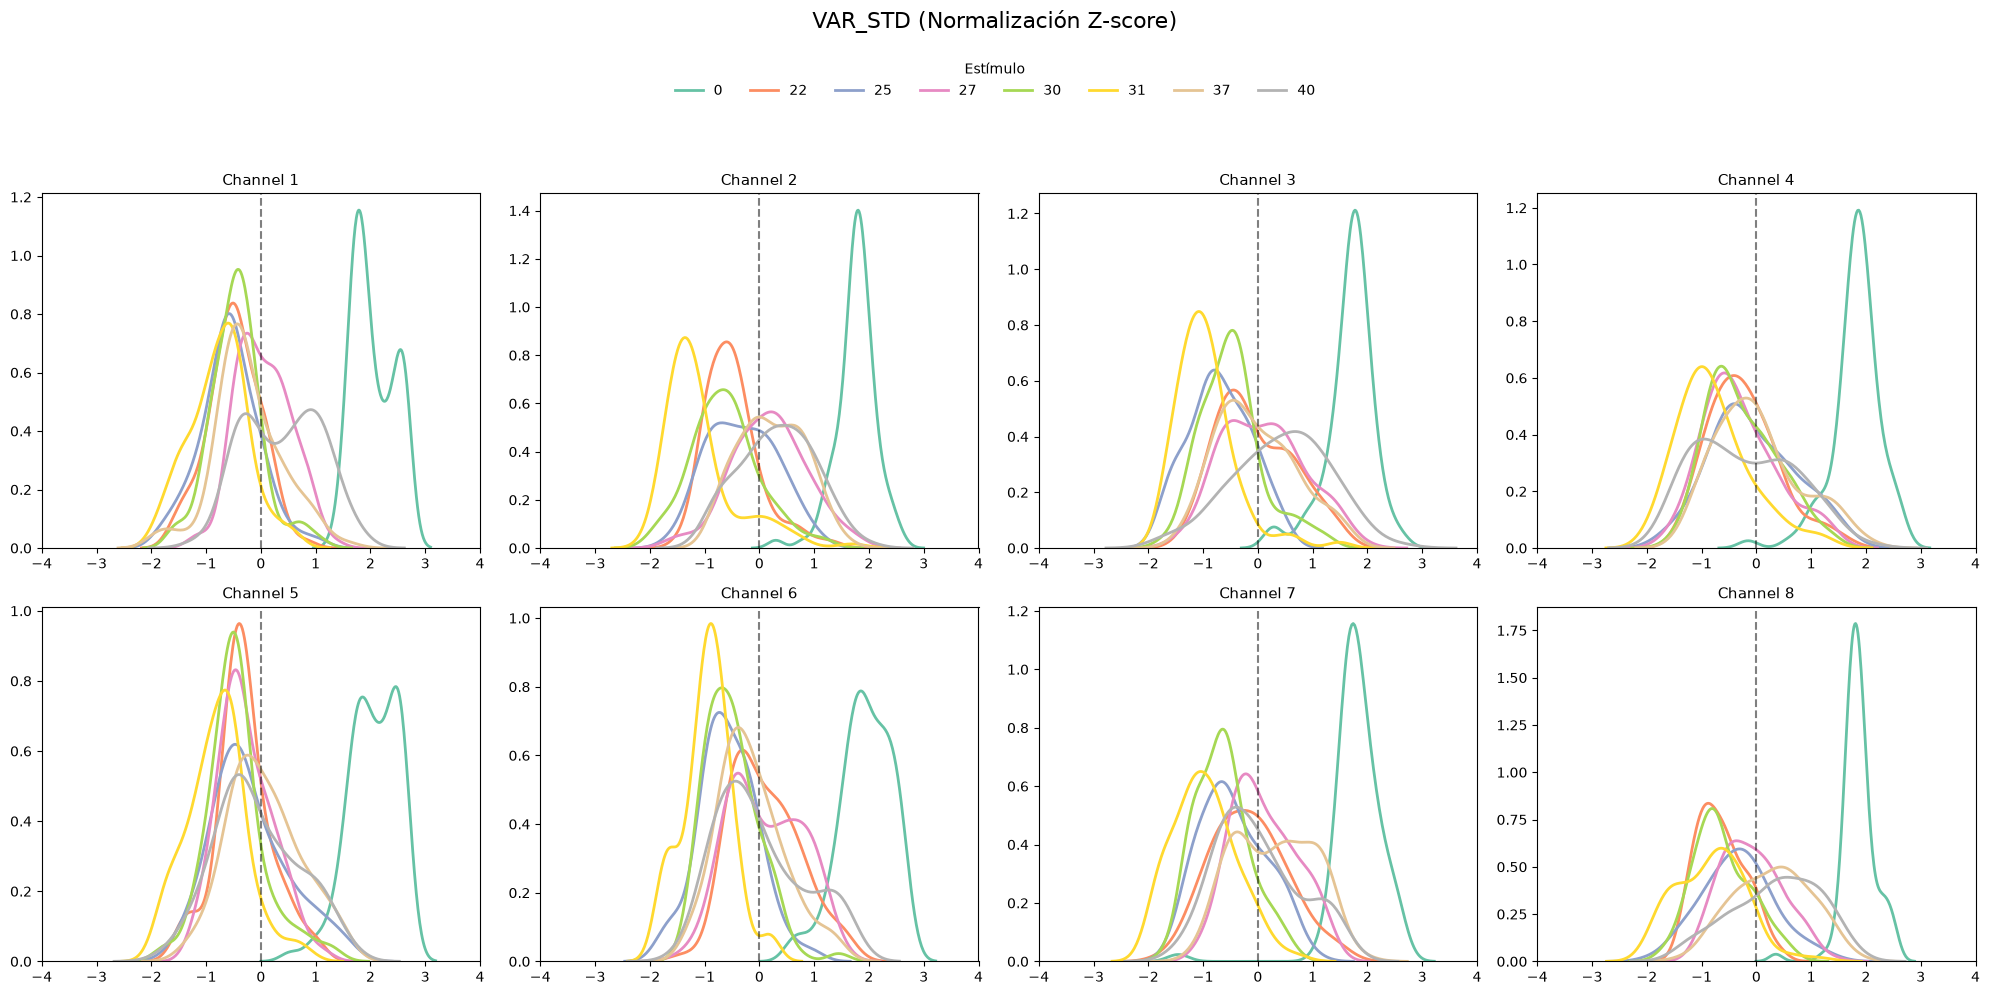

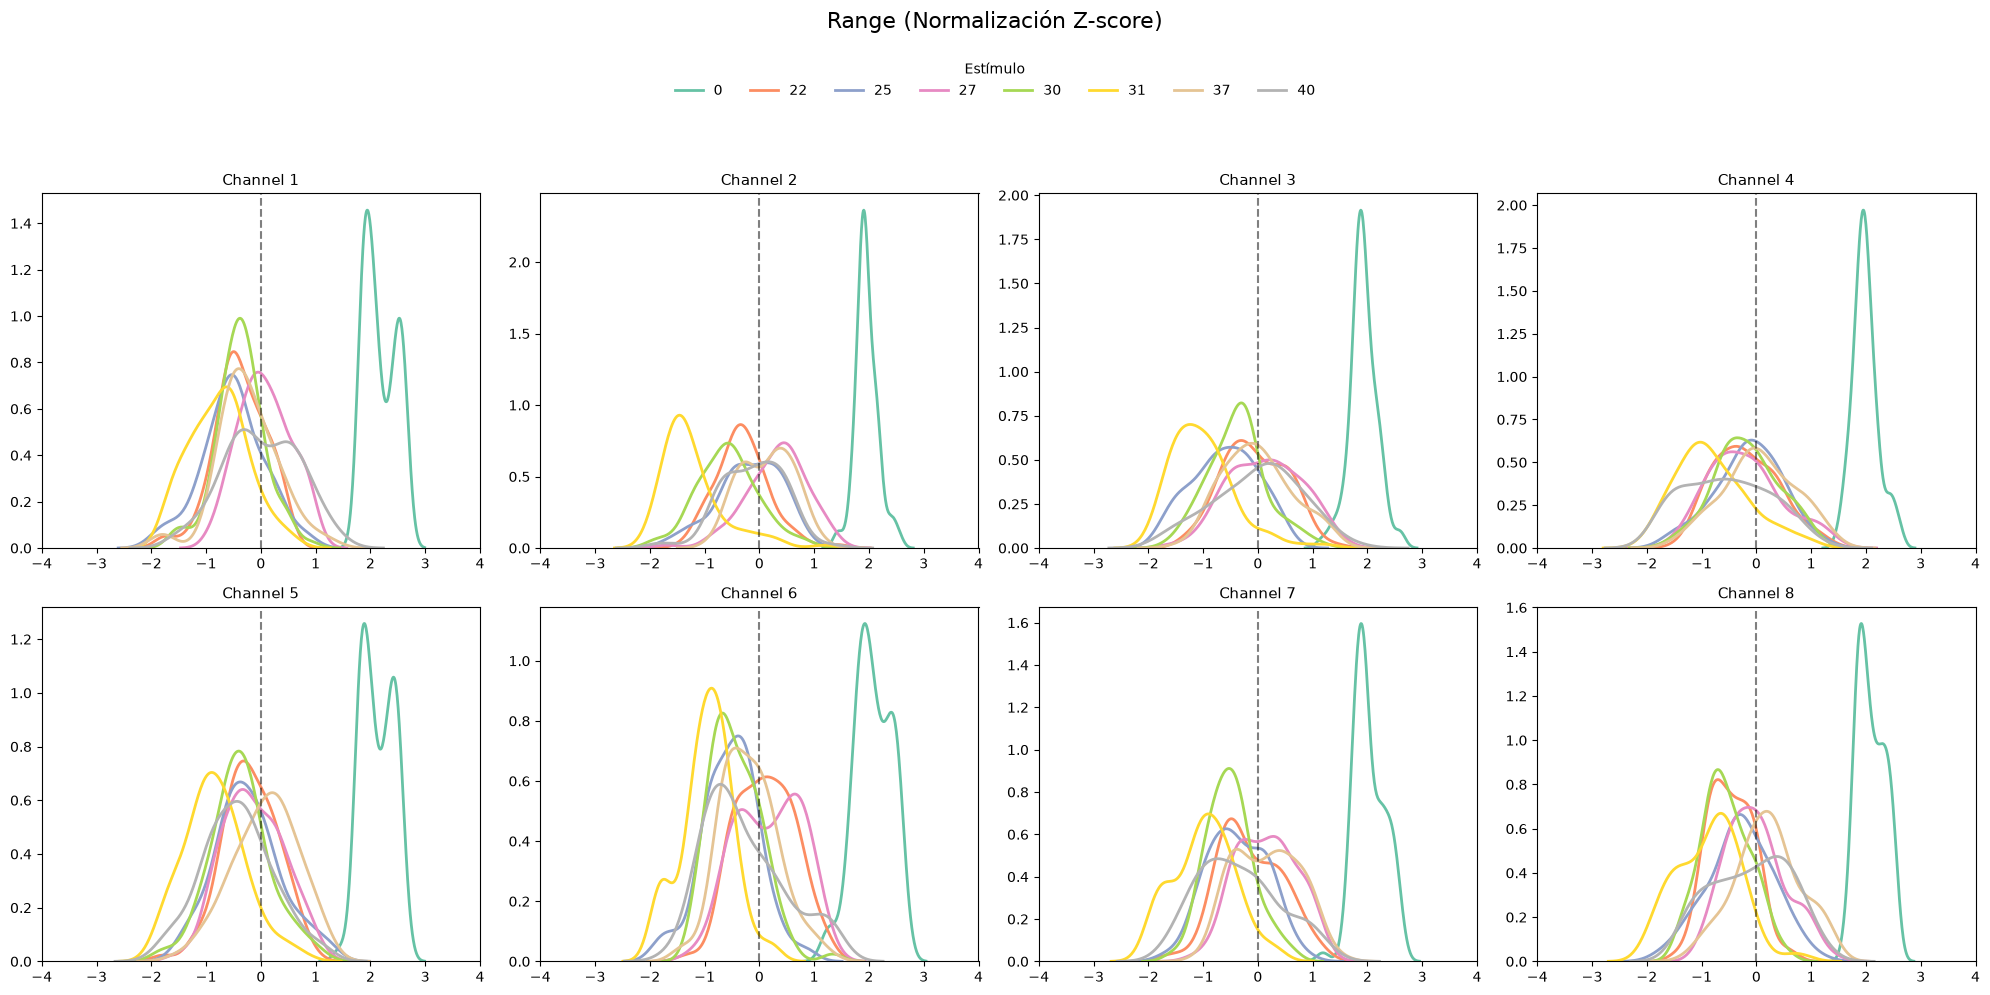

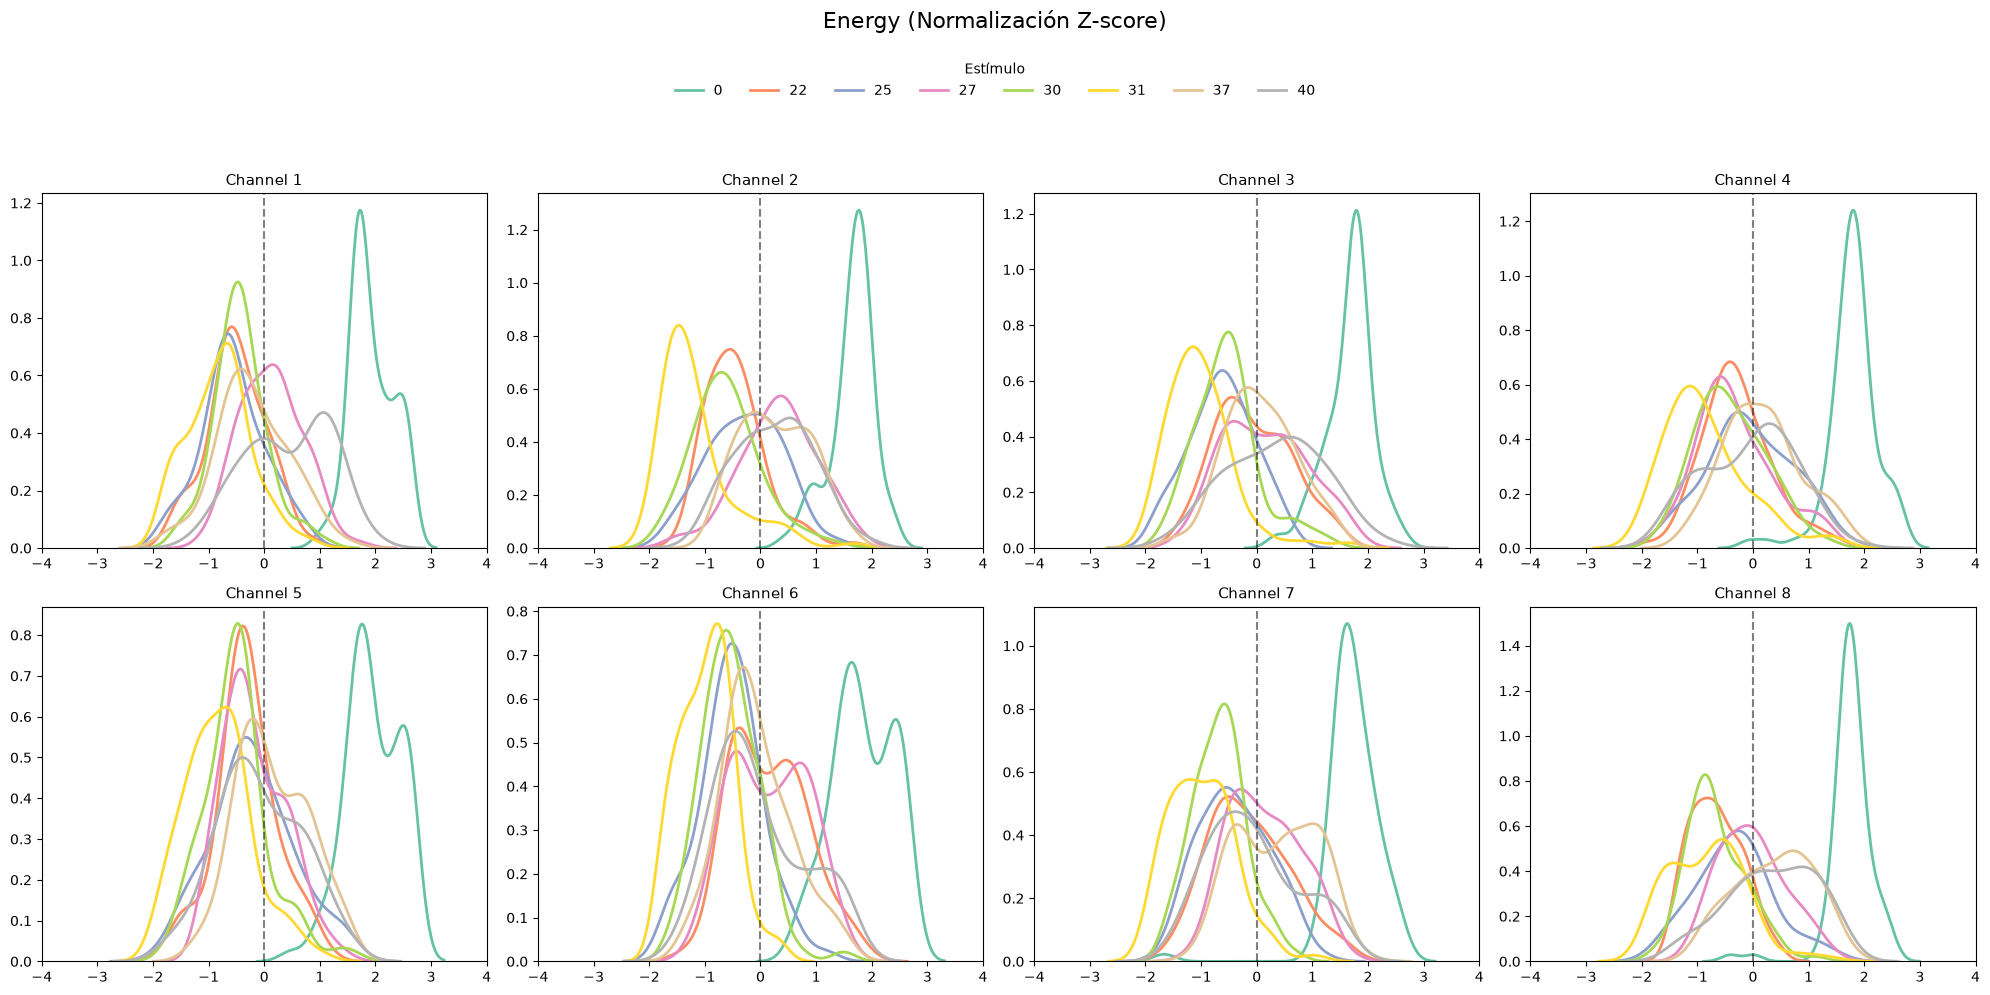

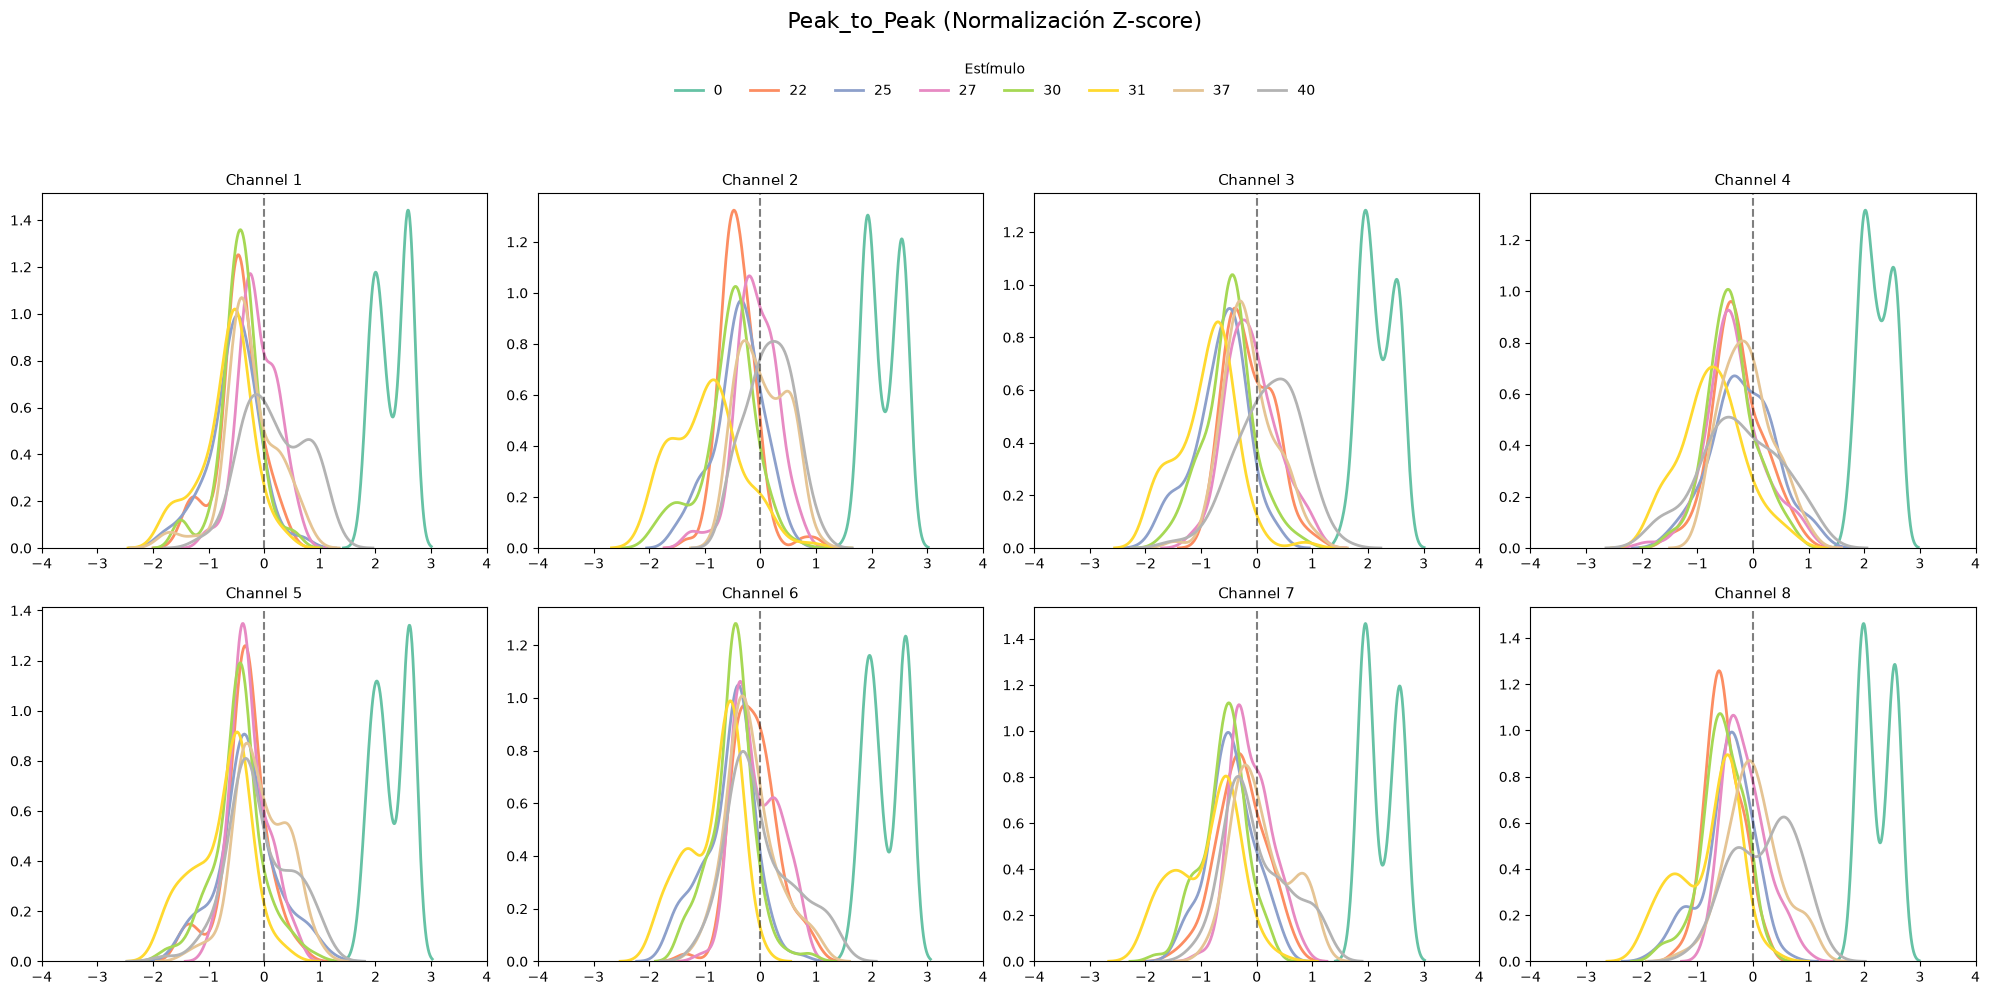

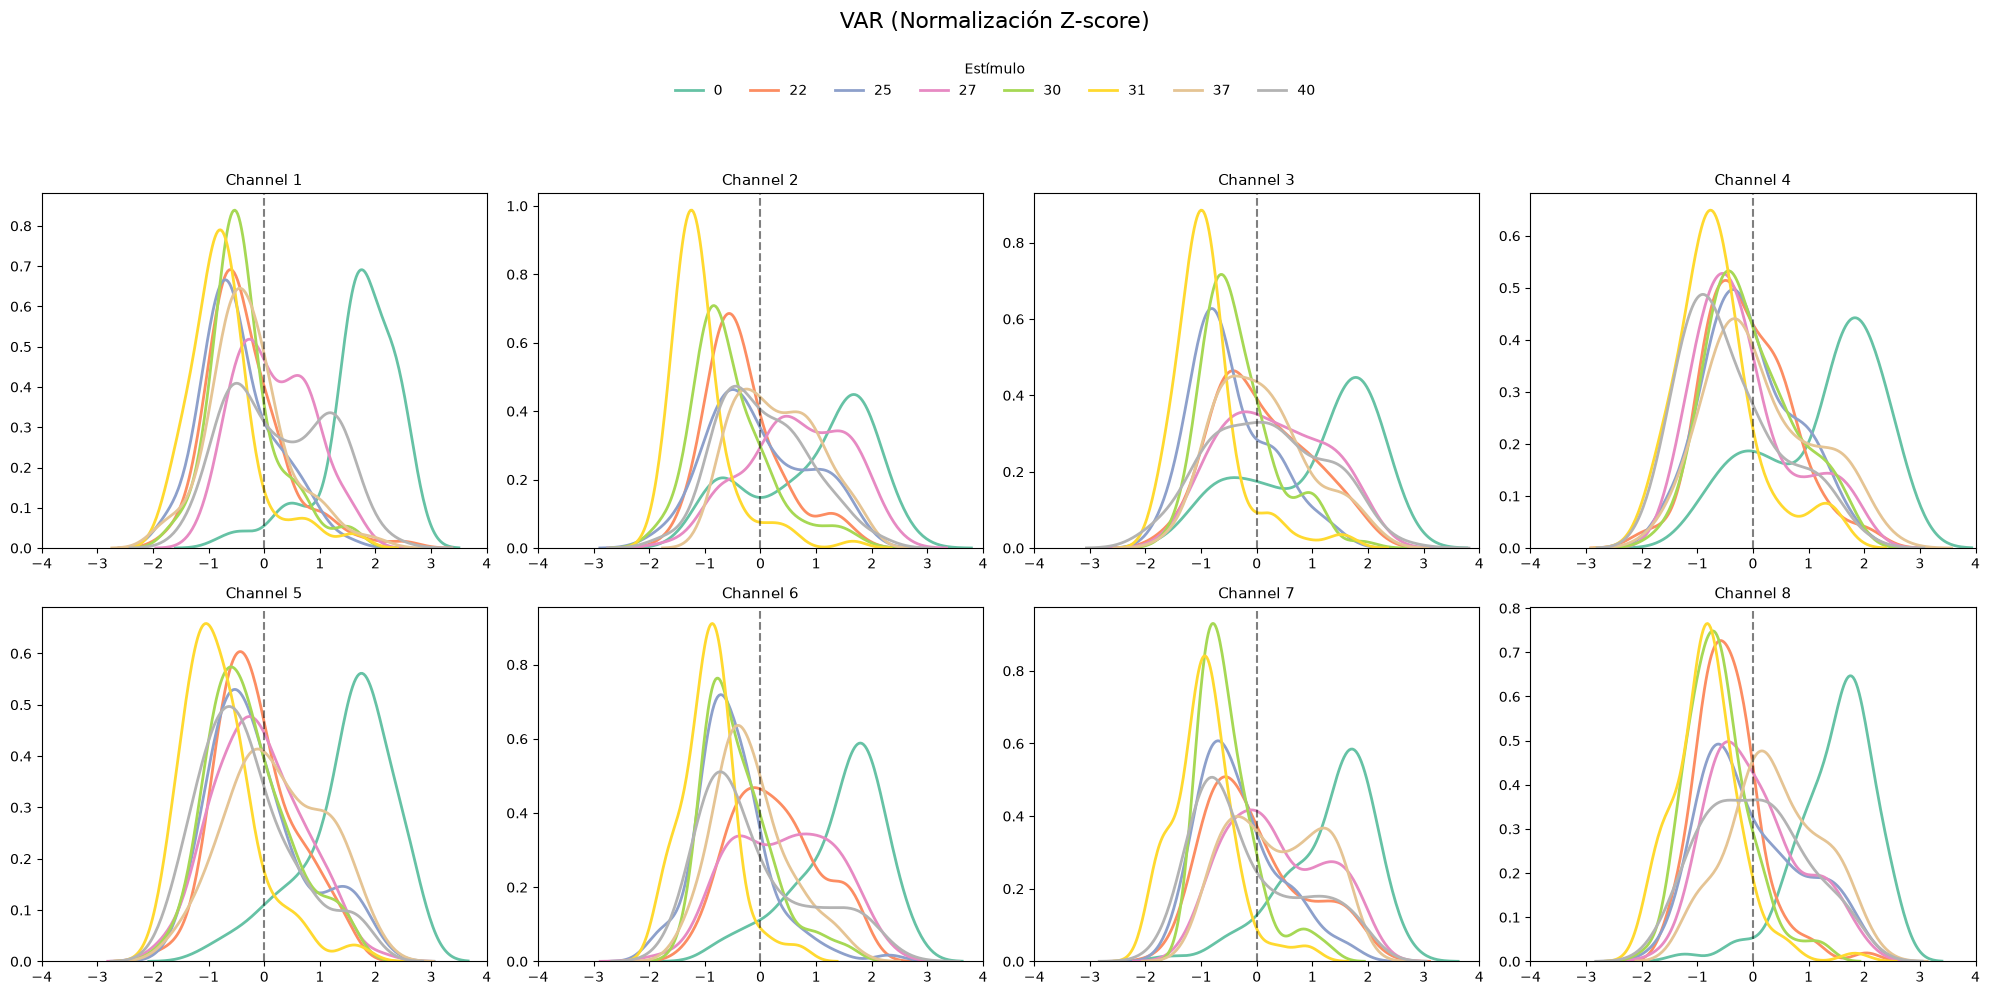

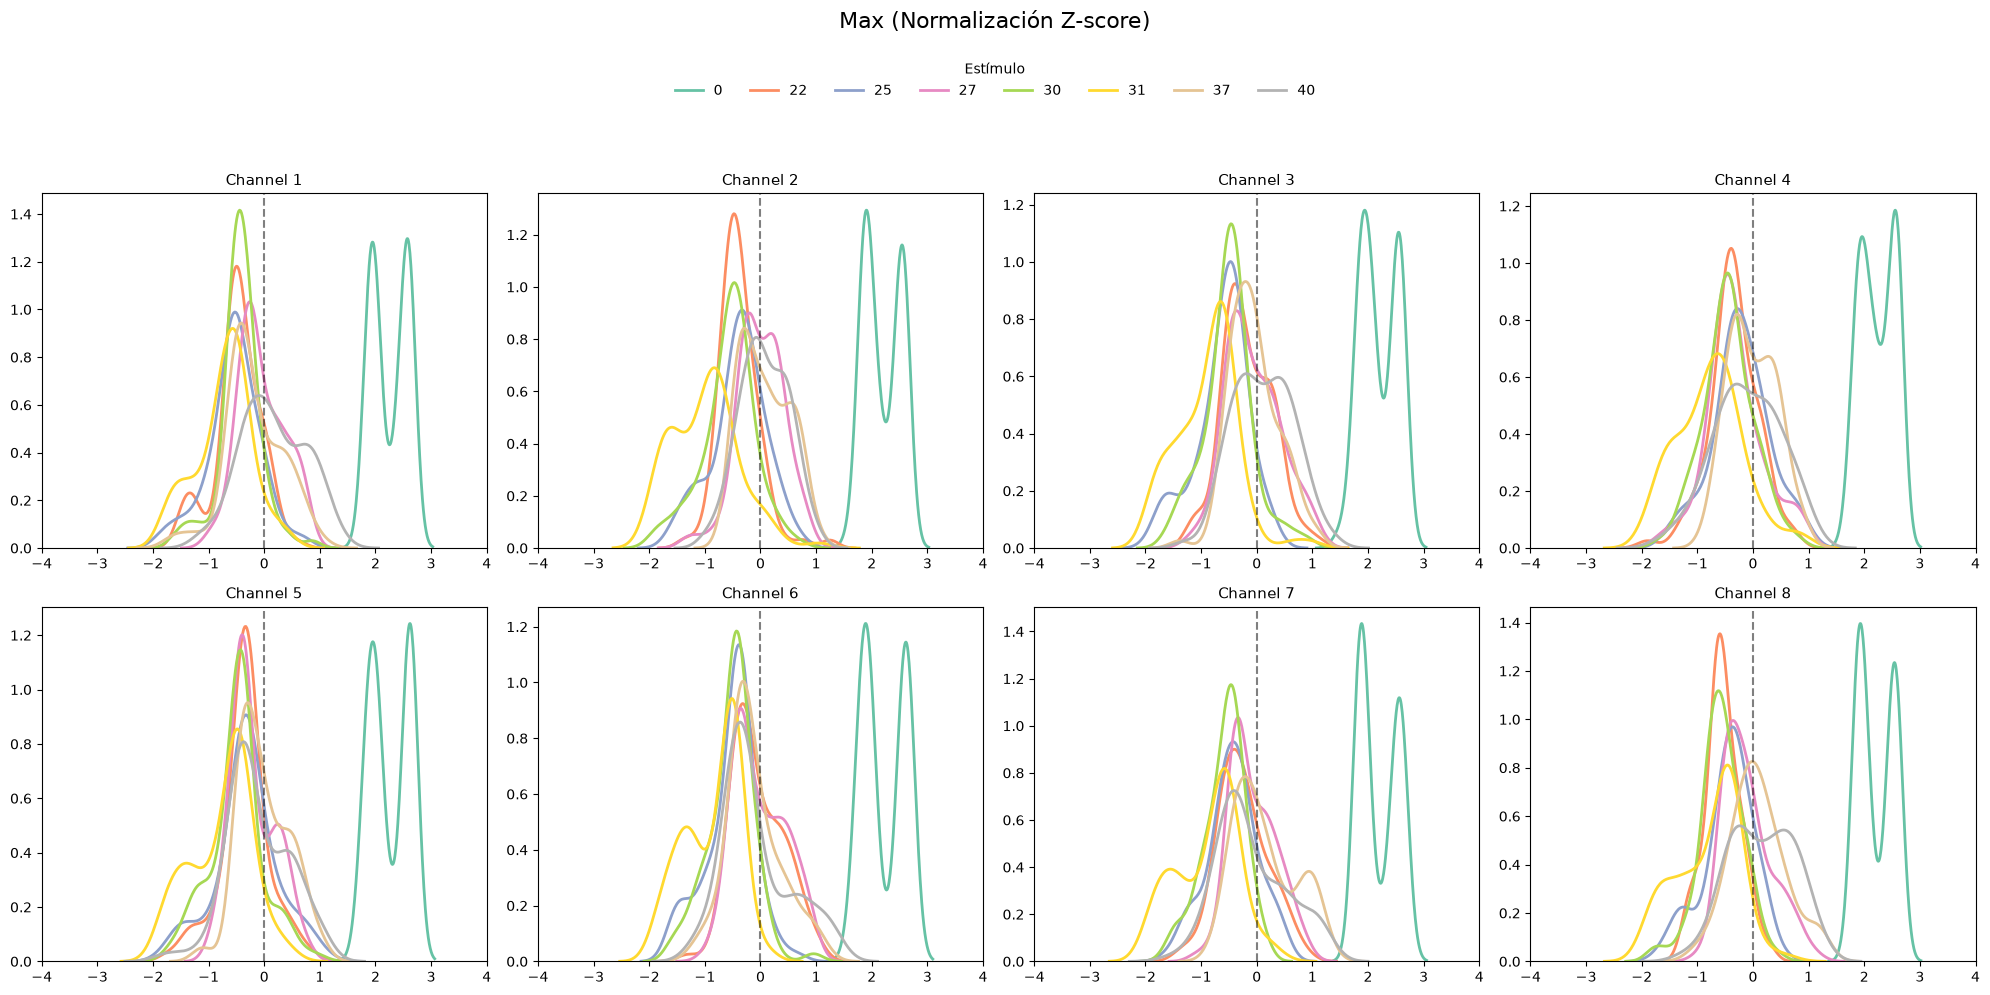

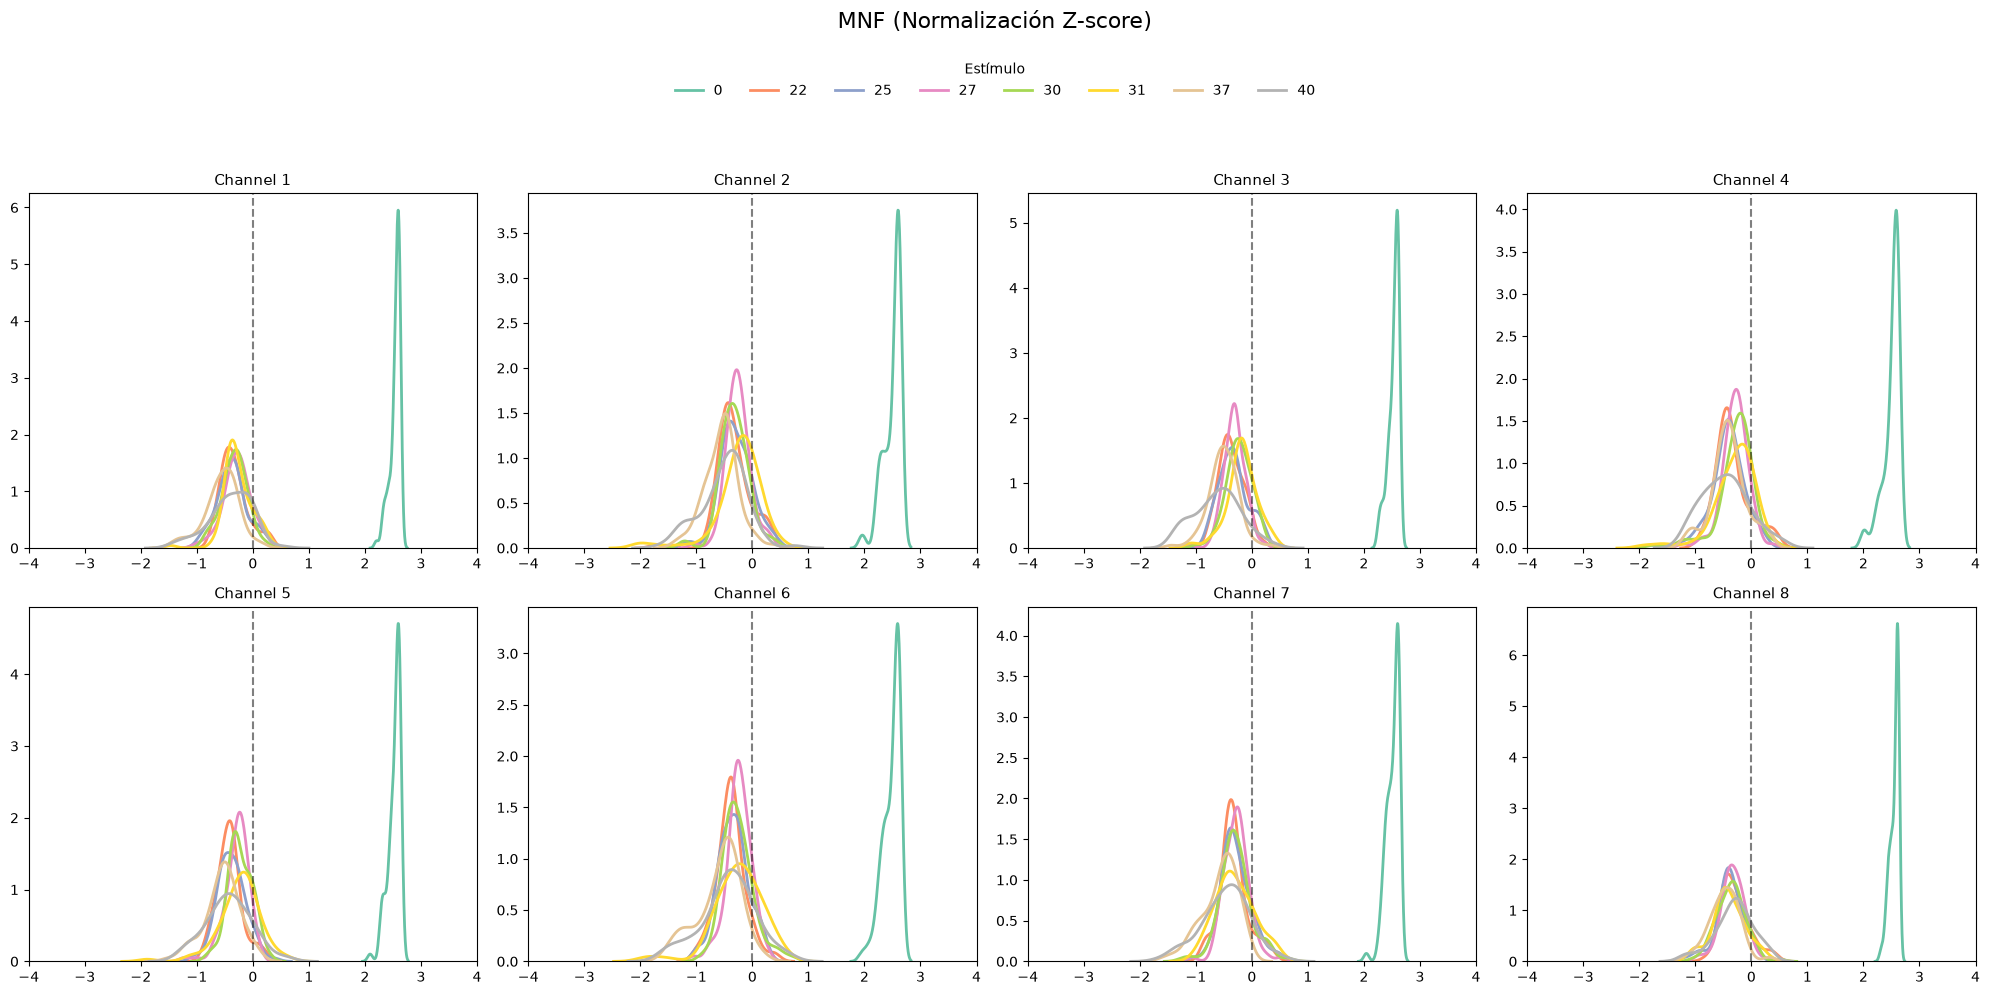

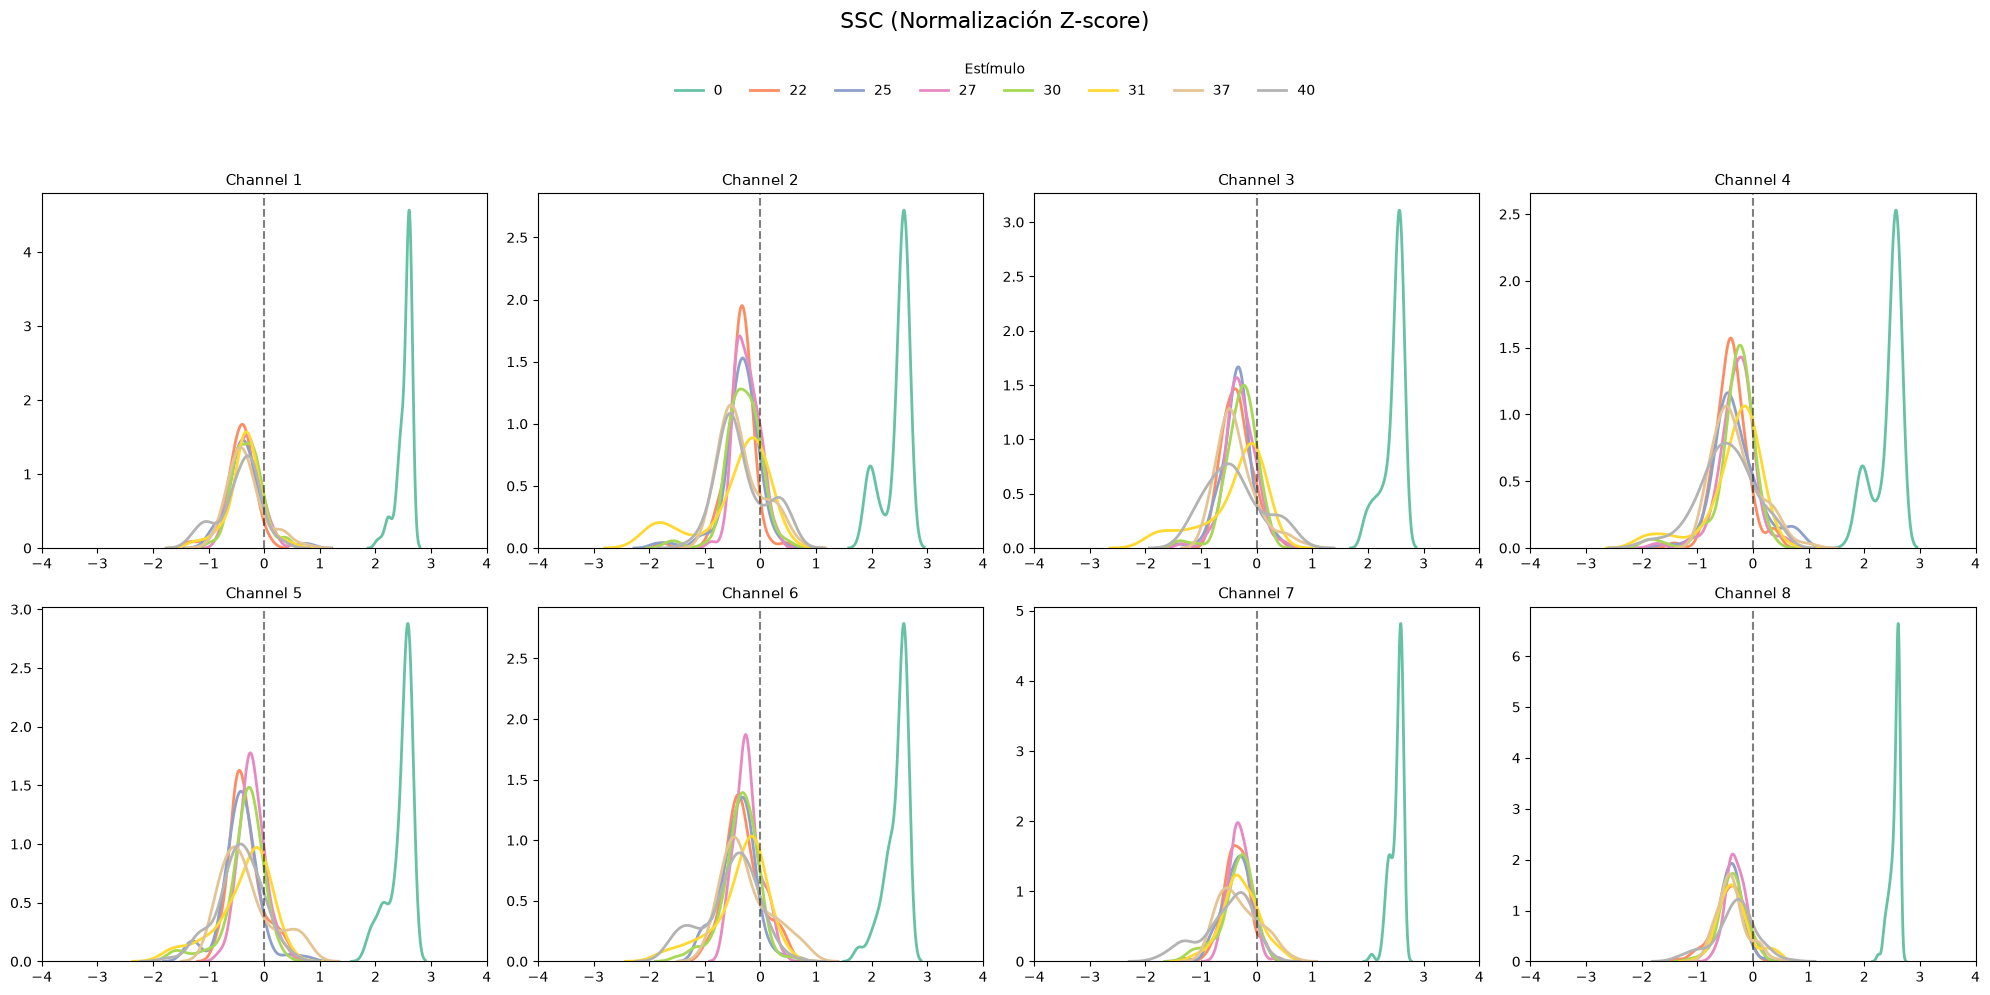

In [12]:
plot_kde_normalized(intact_yj,features)

### Histogramas

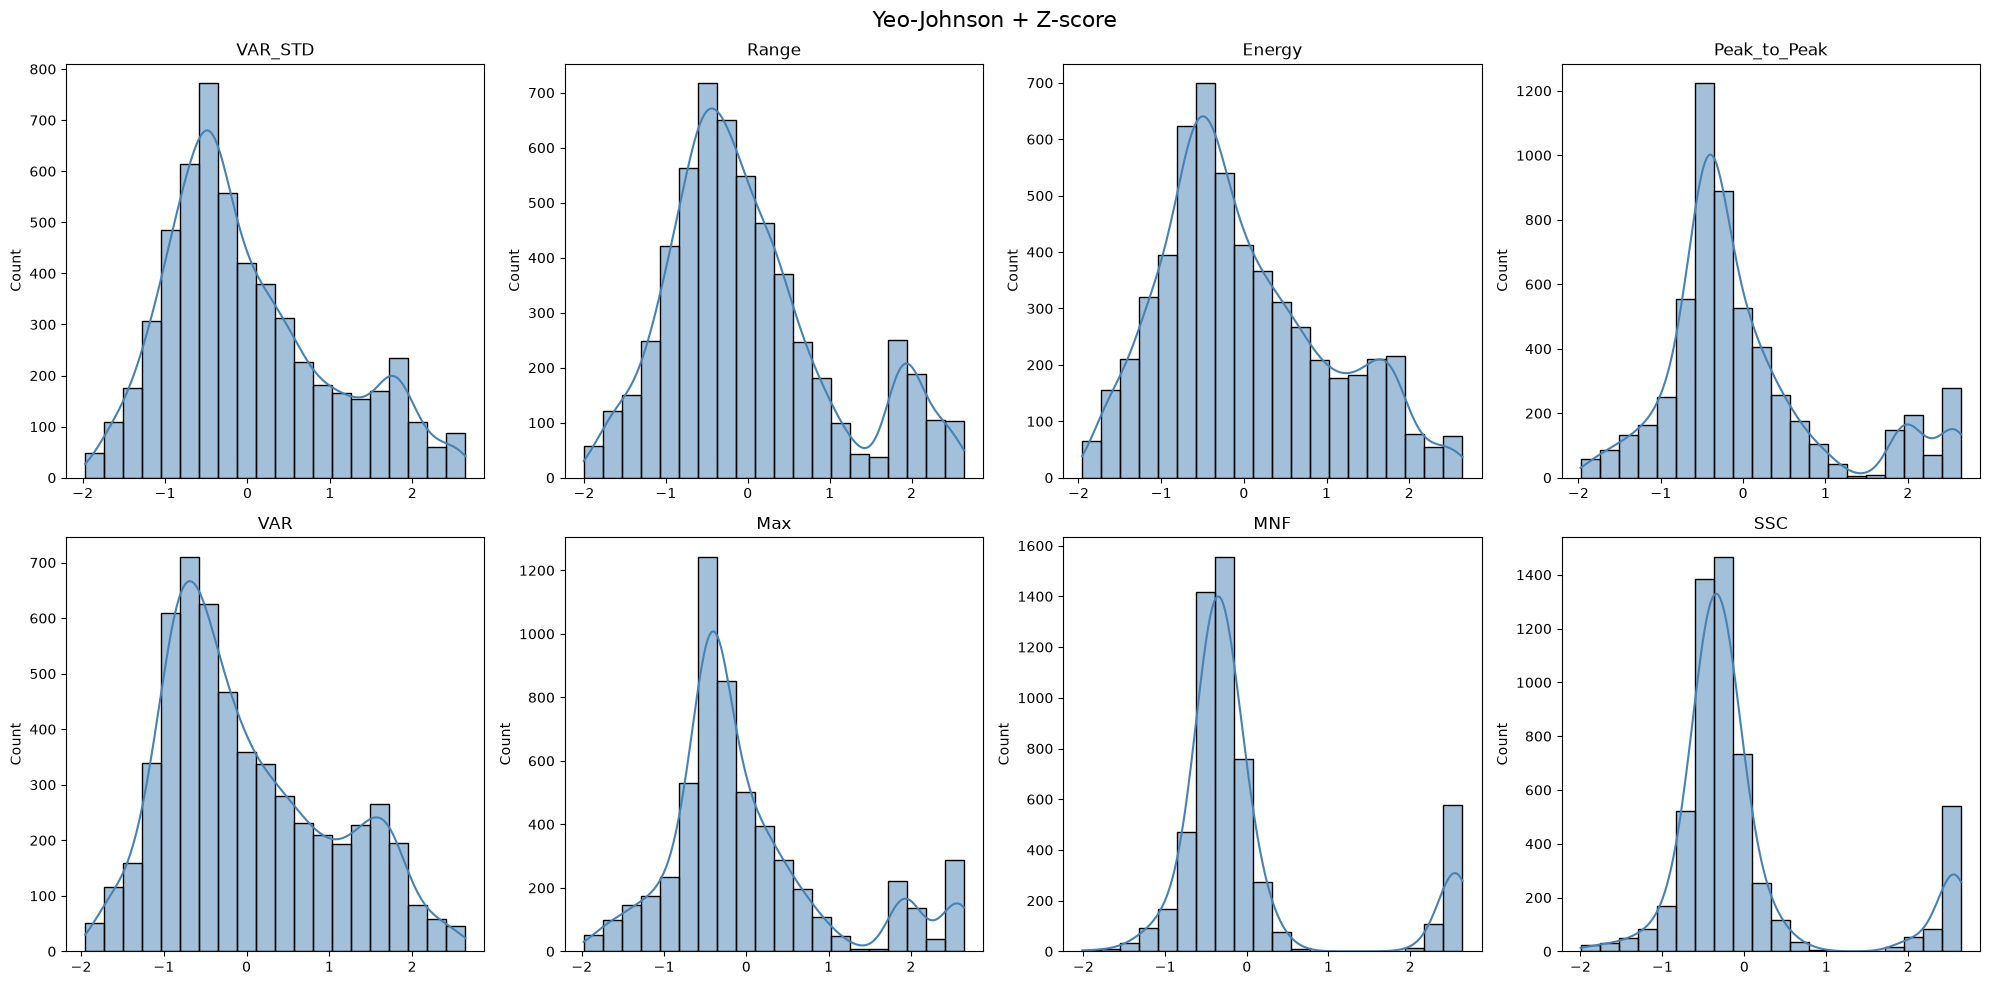

In [13]:
plot_histograms_by_channel(intact_yj,'Yeo-Johnson + Z-score')


# Transformación Box-Cox [subject, origin_db]

In [14]:
# Aplica Box-Cox + Z-score por (subject, origin_db)
def boxcox_by_subject(df, signal_cols):

    # Copia para no modificar el DataFrame original
    df_res = df.copy()

    # Procesar cada sujeto dentro de cada base de datos
    for (subj, db), group in df.groupby(['subject', 'origin_db']):

        # Índices del grupo actual
        idx = group.index

        # Extraer señales como float
        sub_data = df_res.loc[idx, signal_cols].values.astype(float)

        # Box-Cox requiere al menos 2 muestras y valores estrictamente positivos
        if sub_data.shape[0] < 2 or np.any(sub_data <= 0):
            continue

        # Ajustar Box-Cox y aplicar estandarización posterior
        transformer = PowerTransformer(
            method='box-cox',
            standardize=True
        )

        # Reemplazar datos originales por los transformados
        df_res.loc[idx, signal_cols] = transformer.fit_transform(sub_data)

    return df_res

intact_bc = boxcox_by_subject(intact, signal_cols)
intact_bc.to_csv("../data/processed/intact_bc.csv", index=False)

### Todos los estímulos por canal

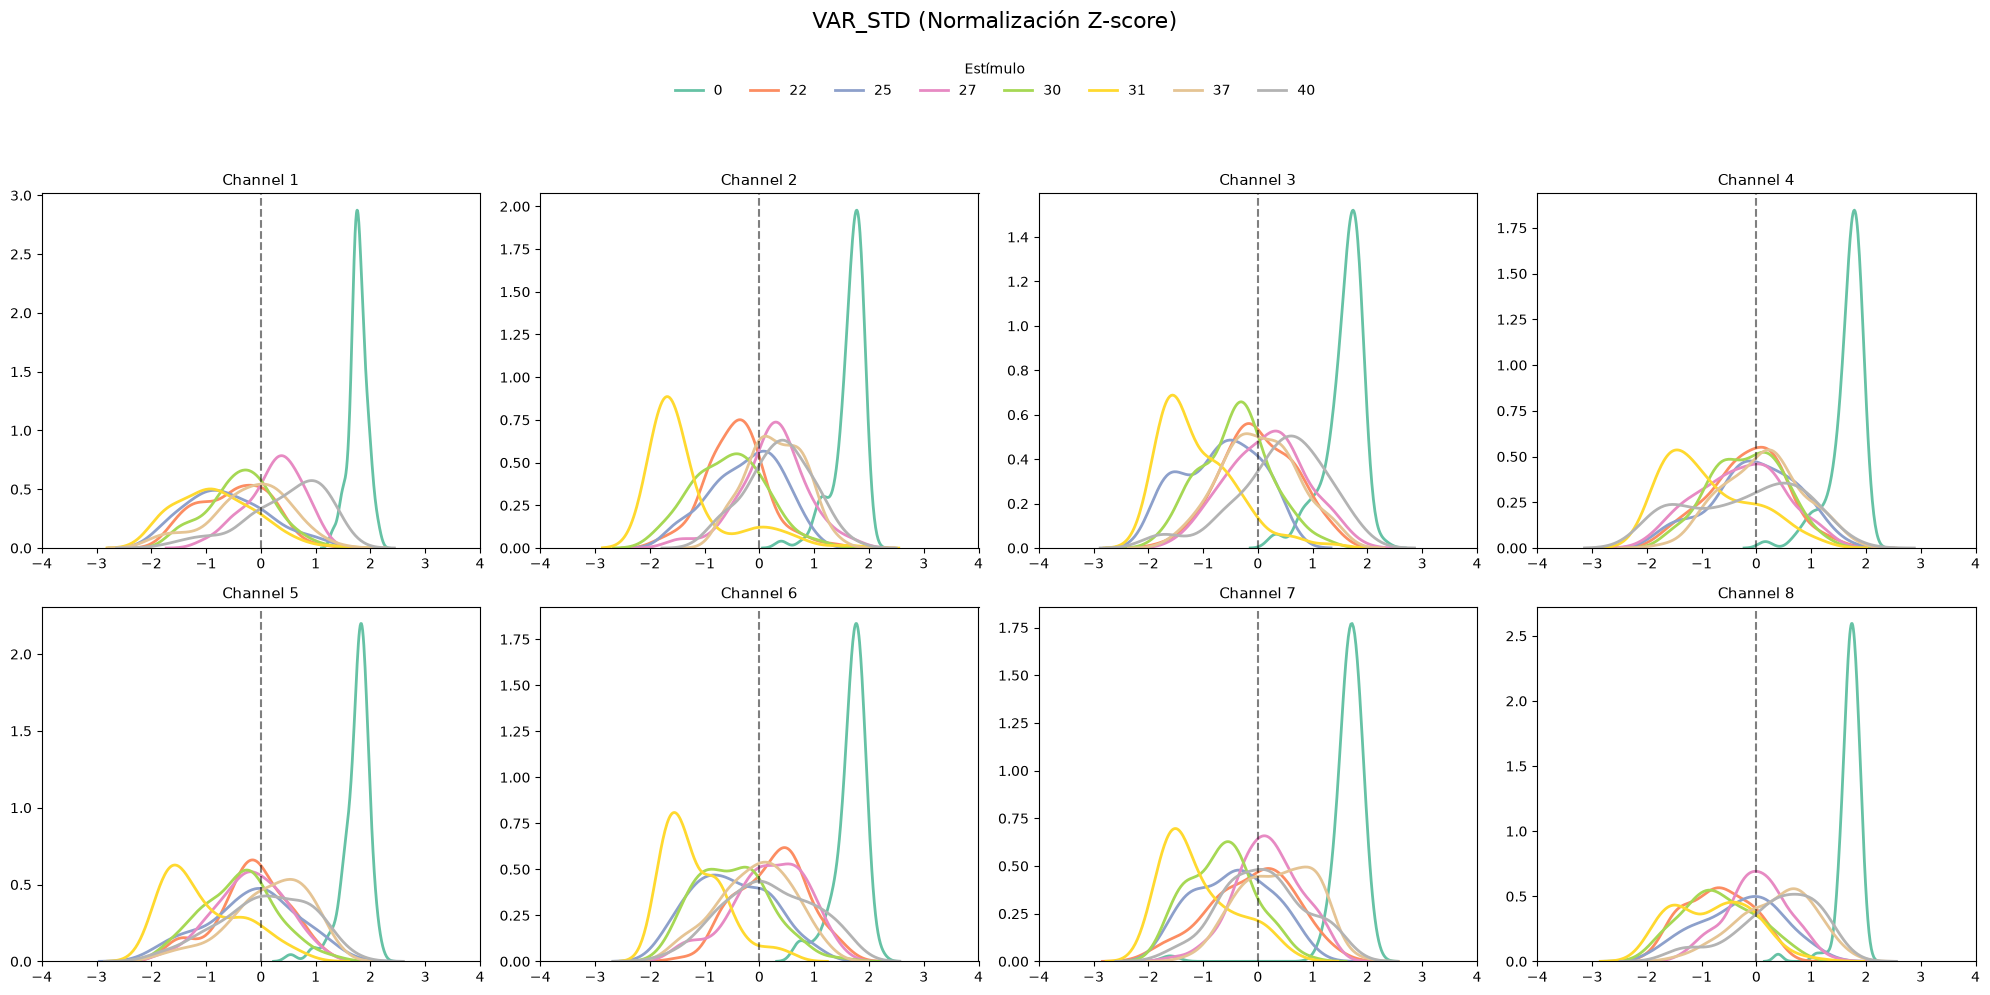

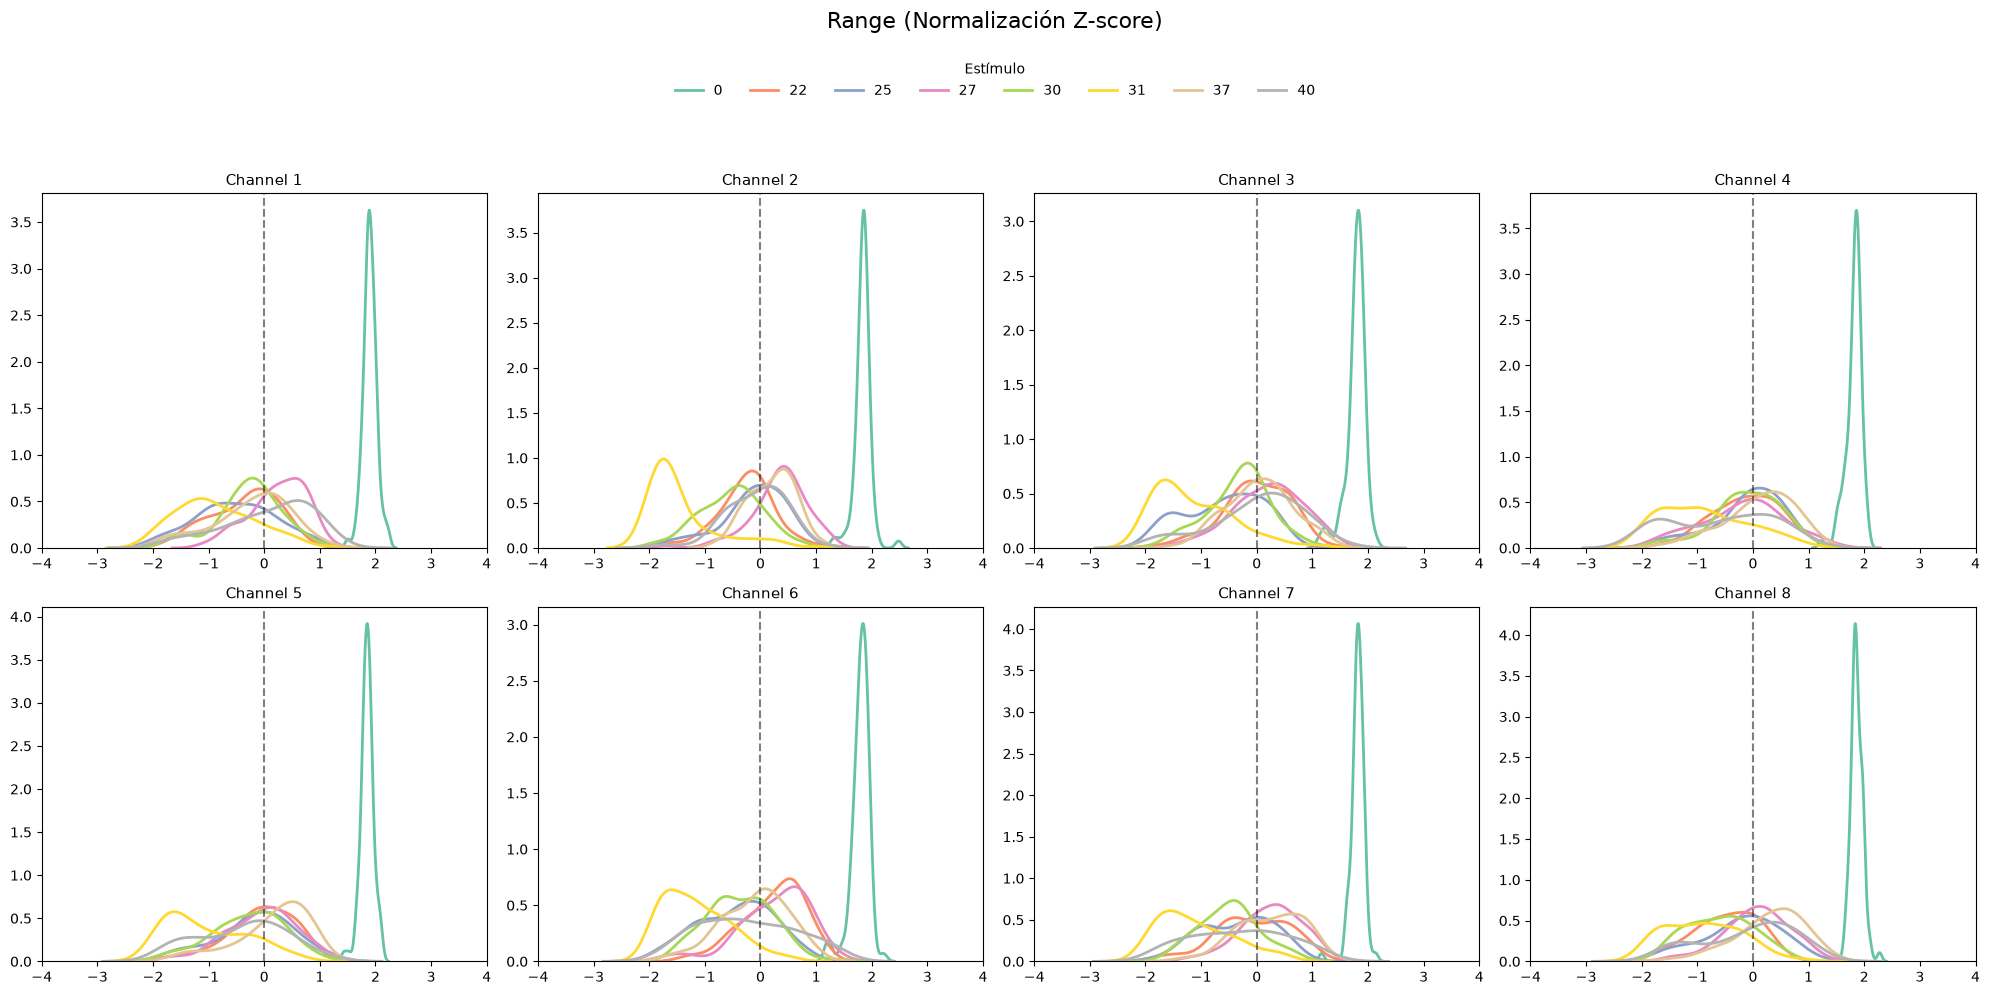

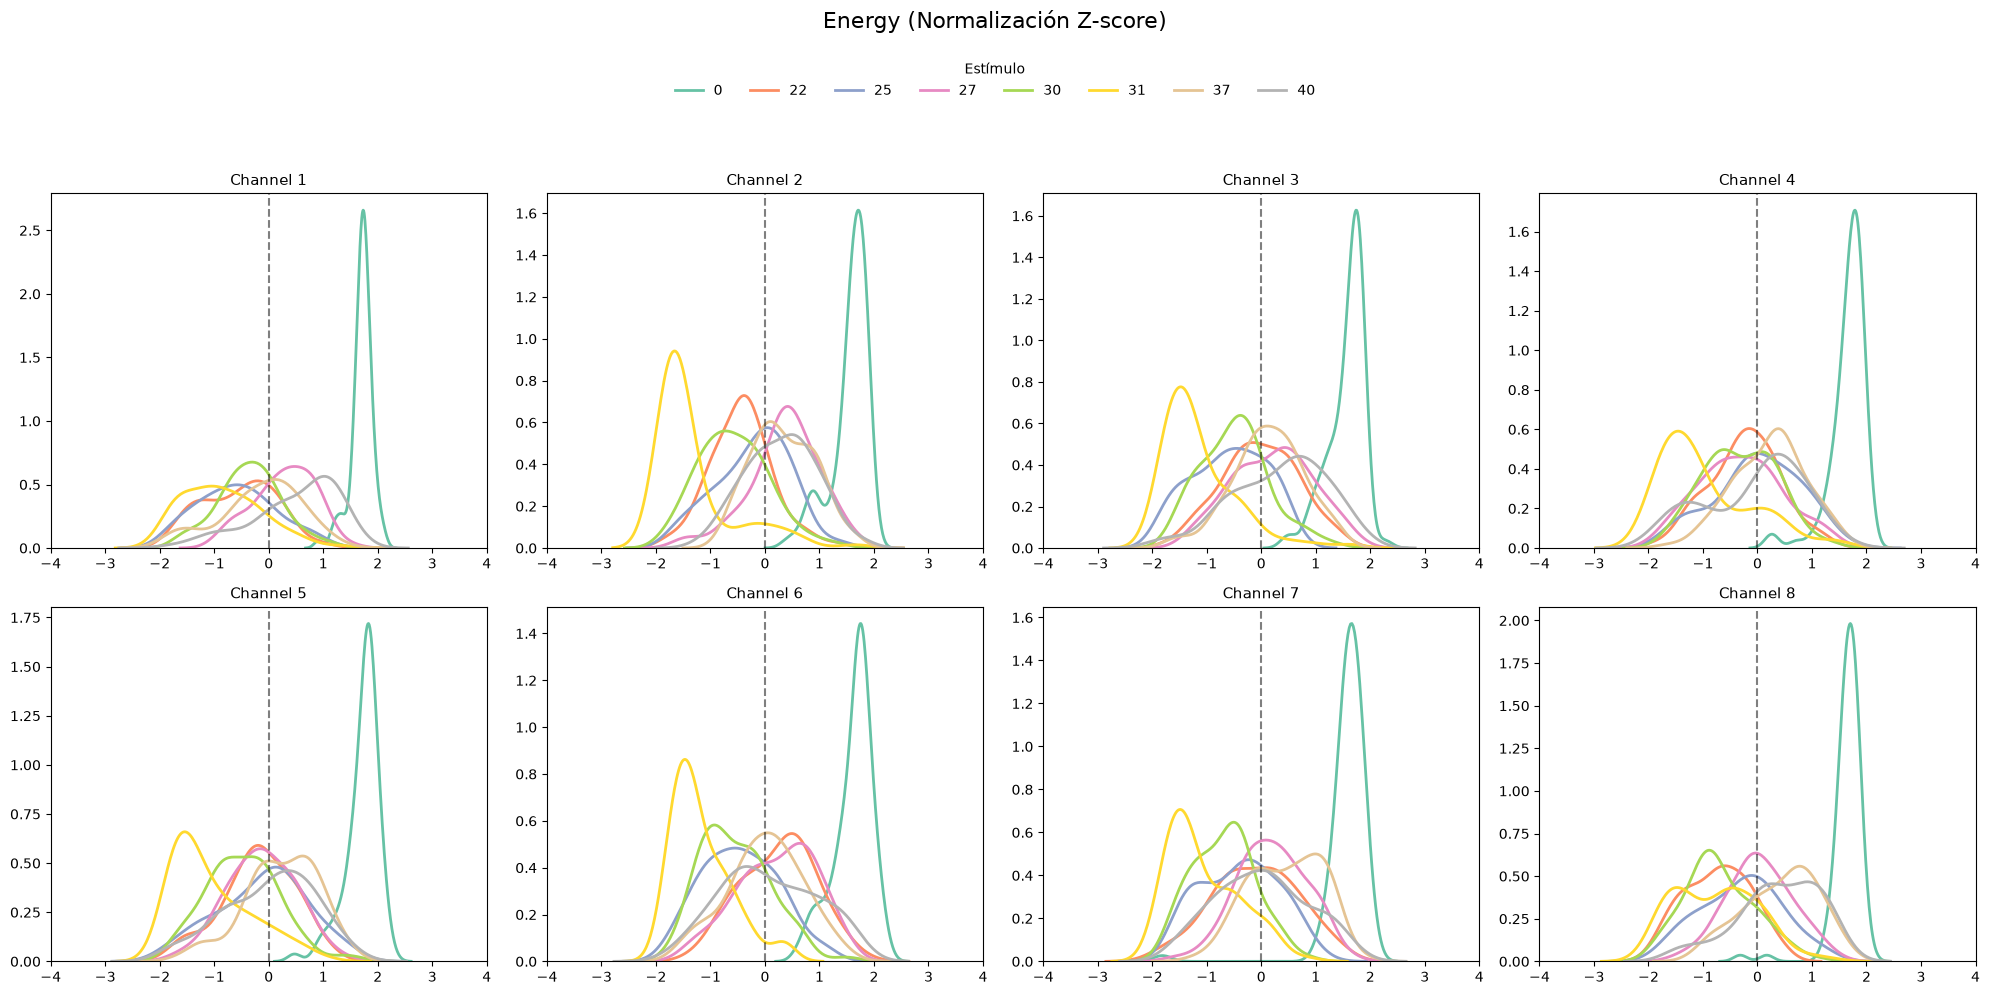

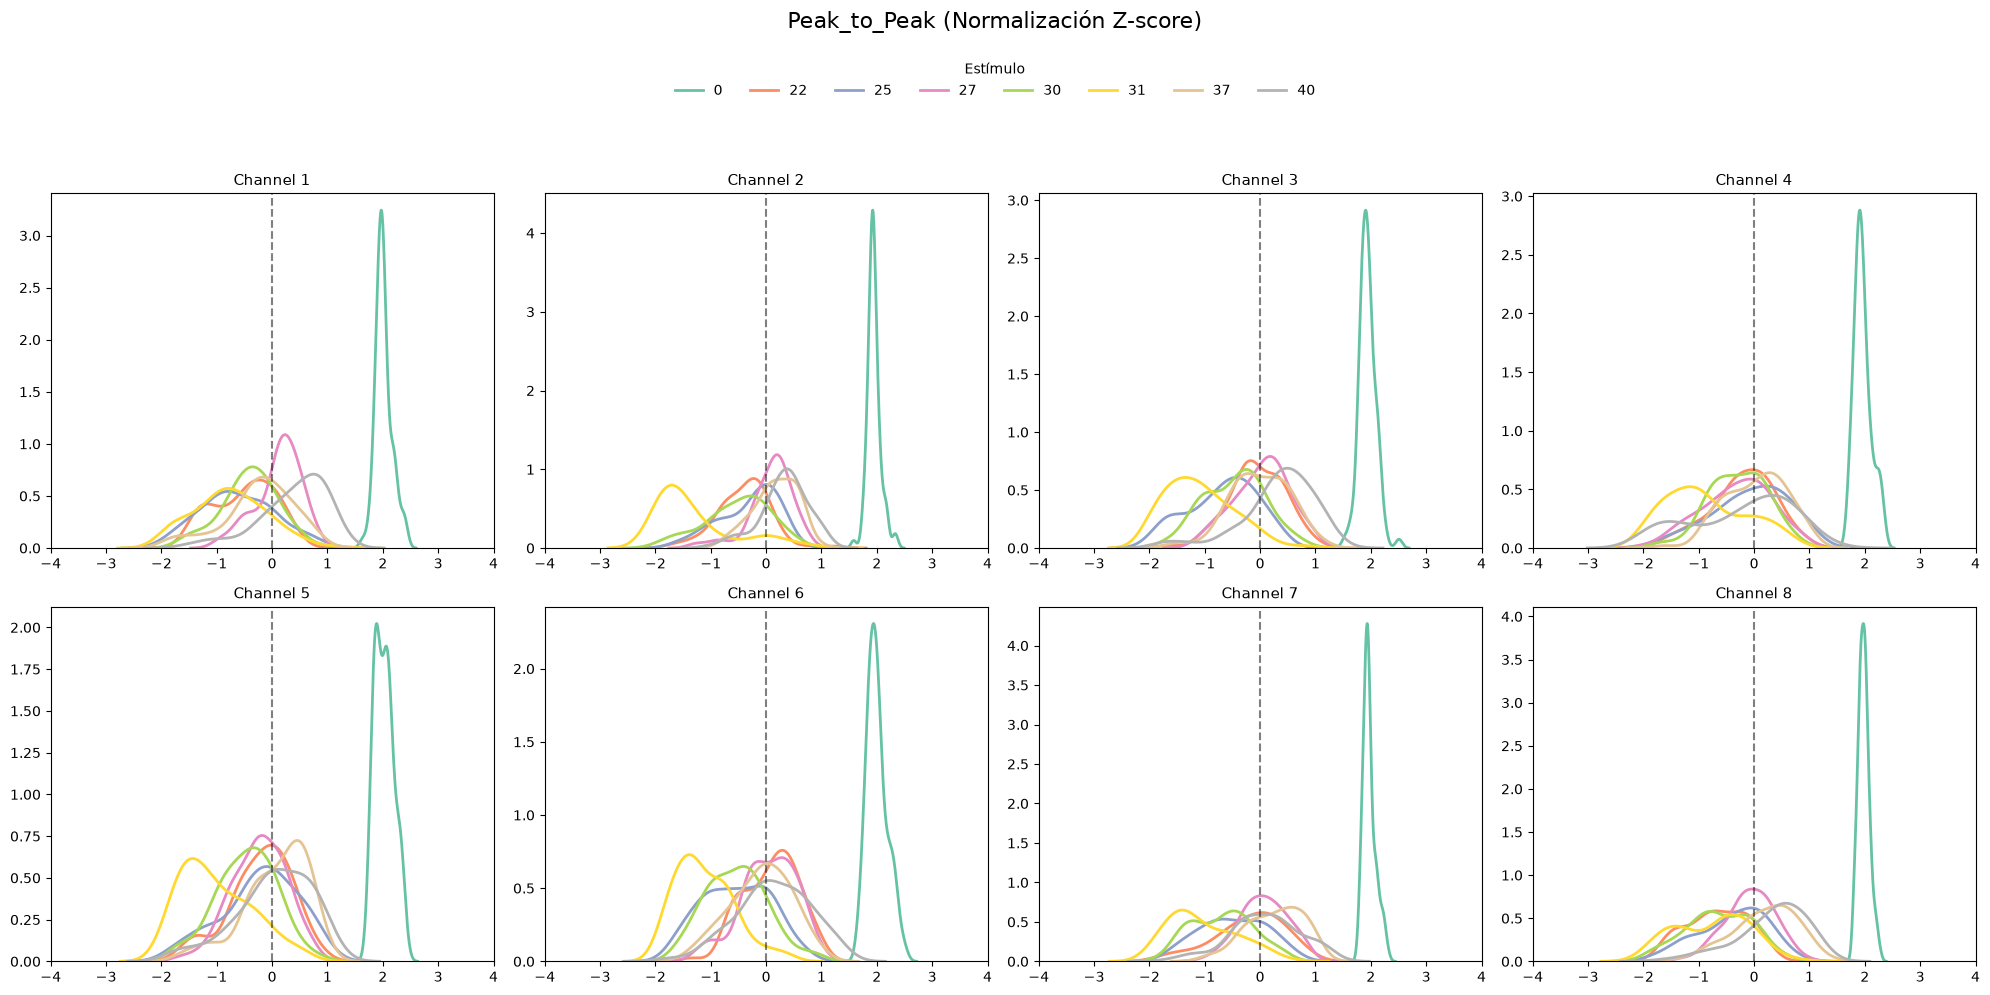

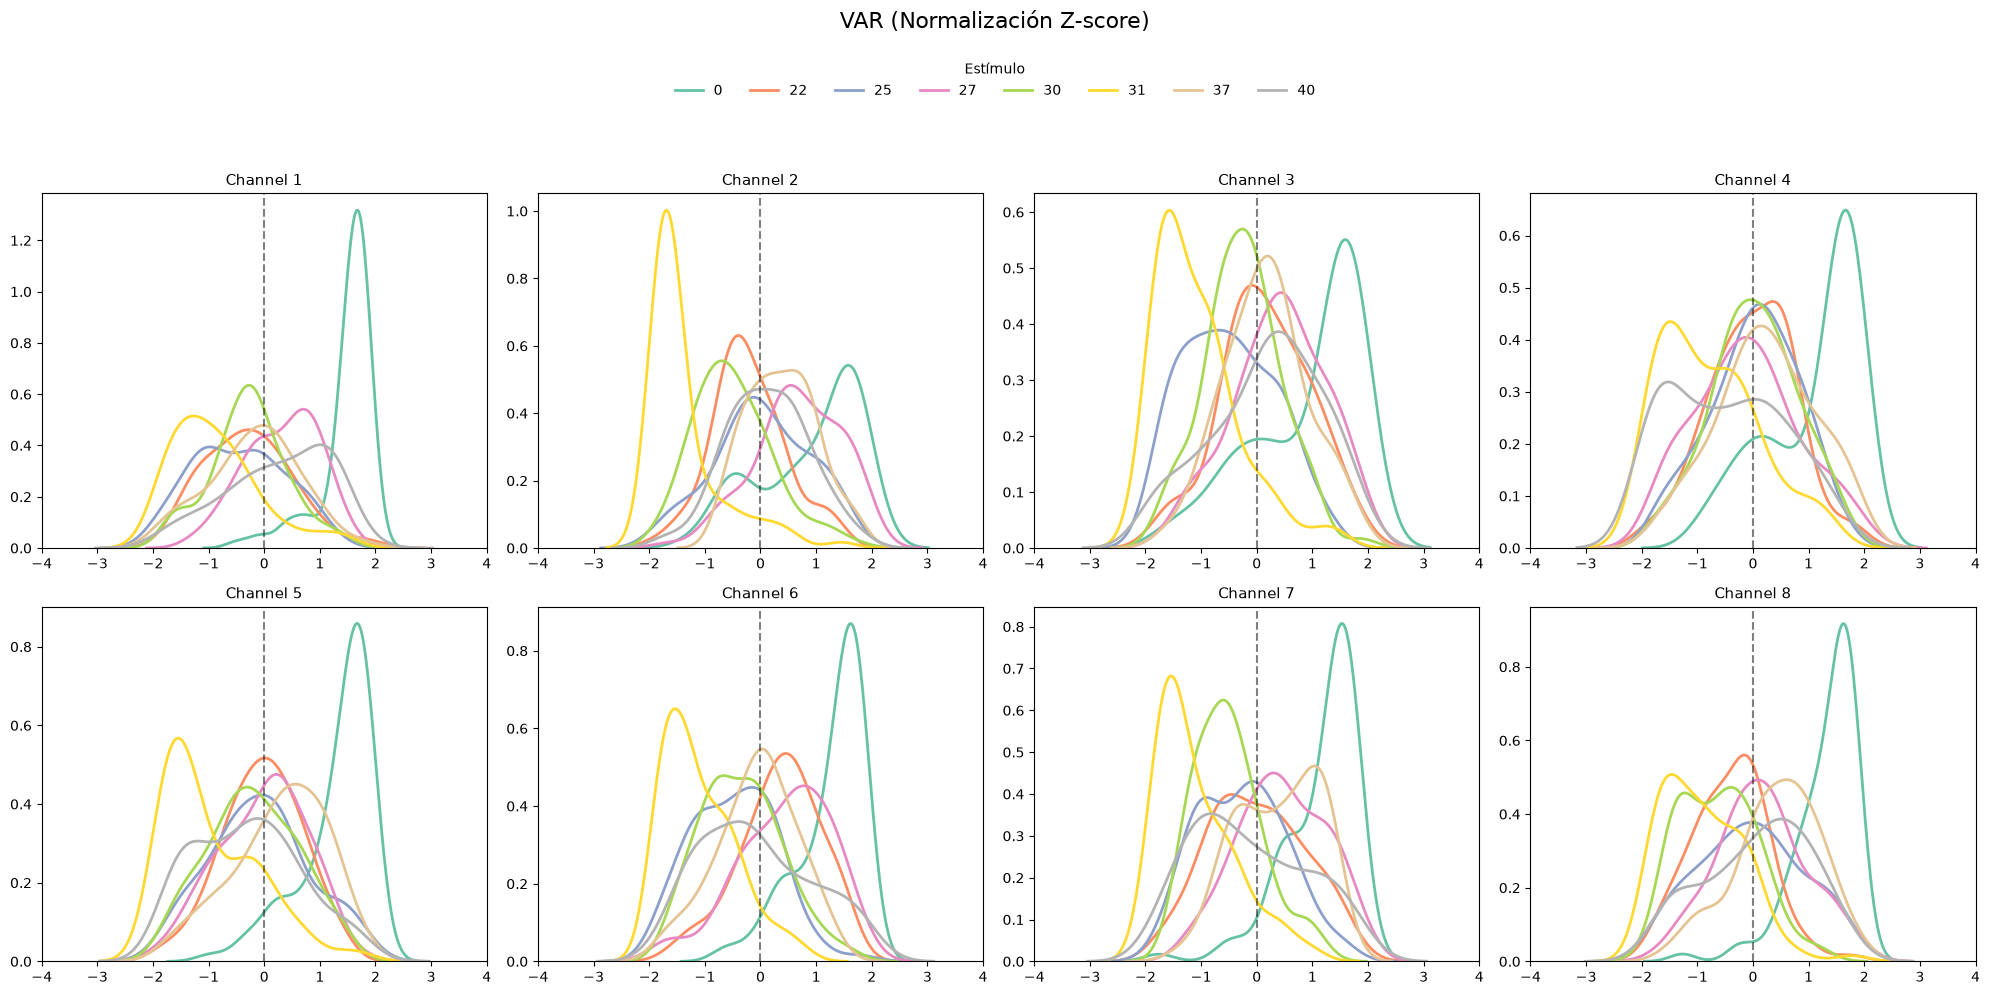

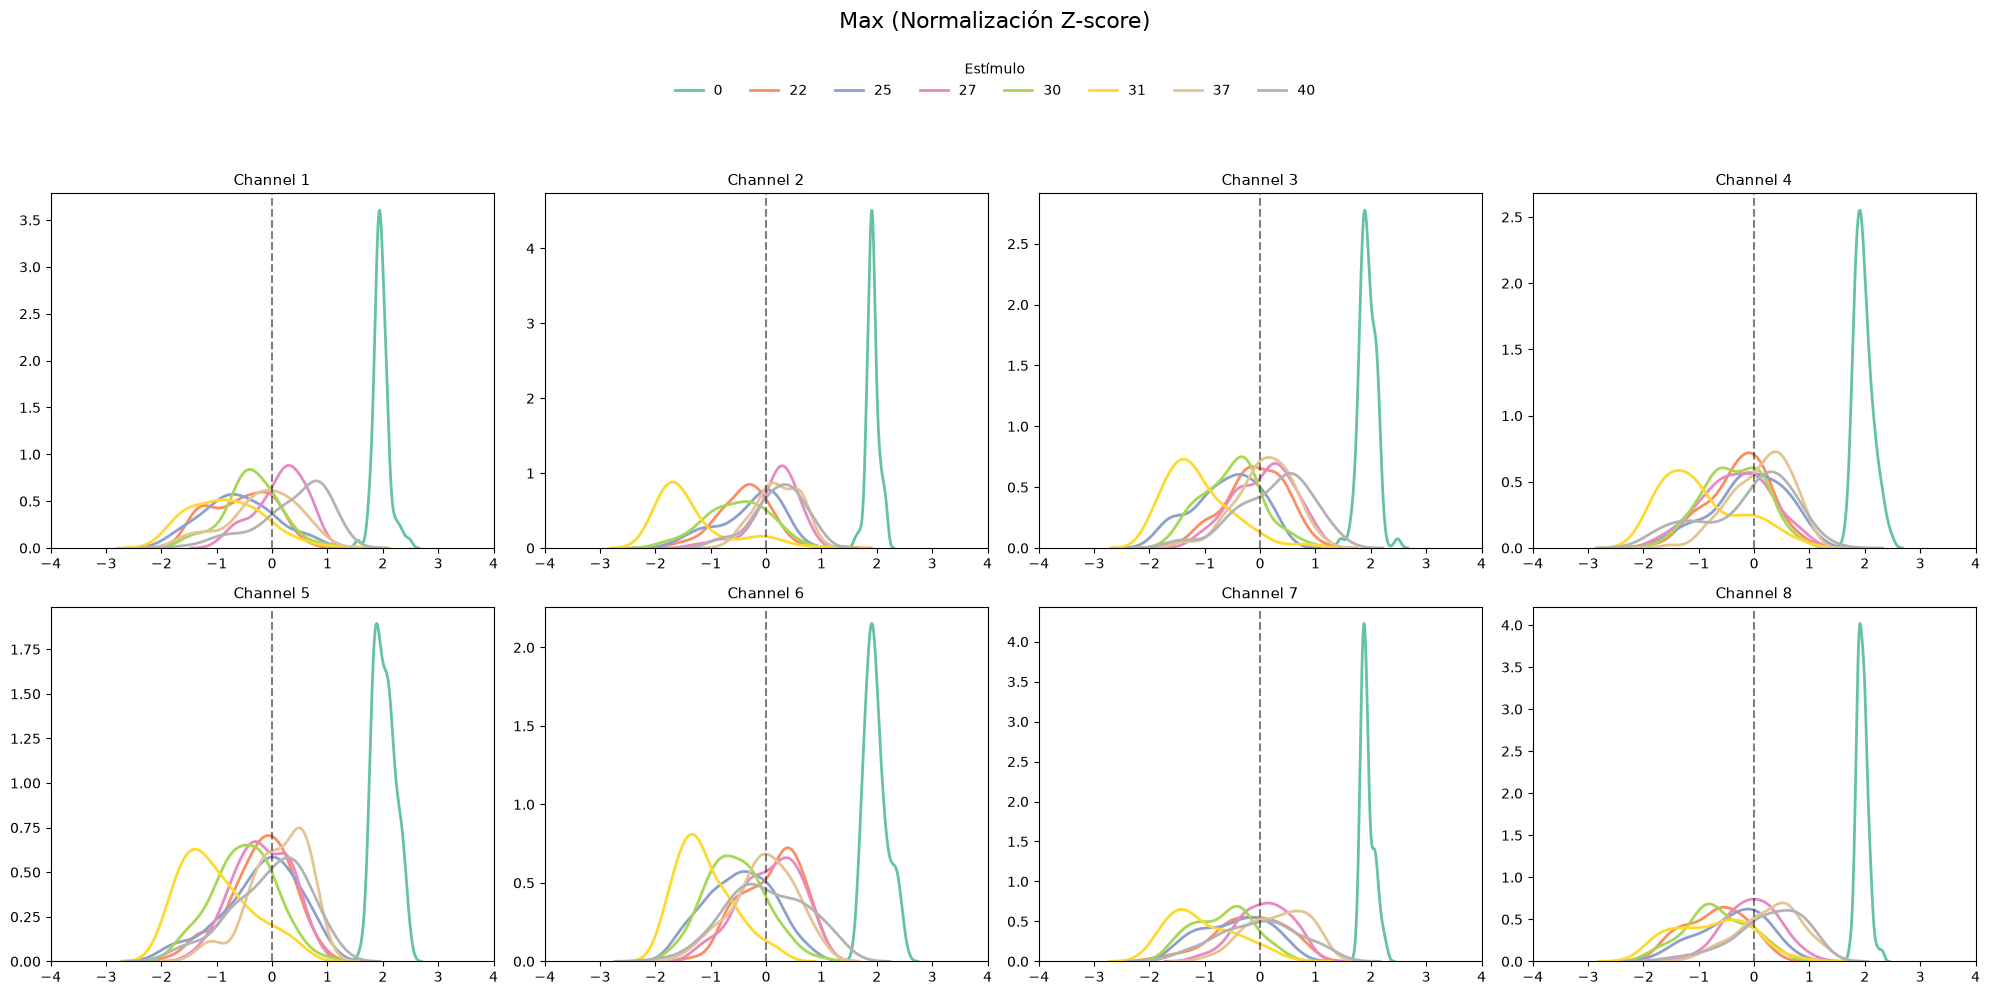

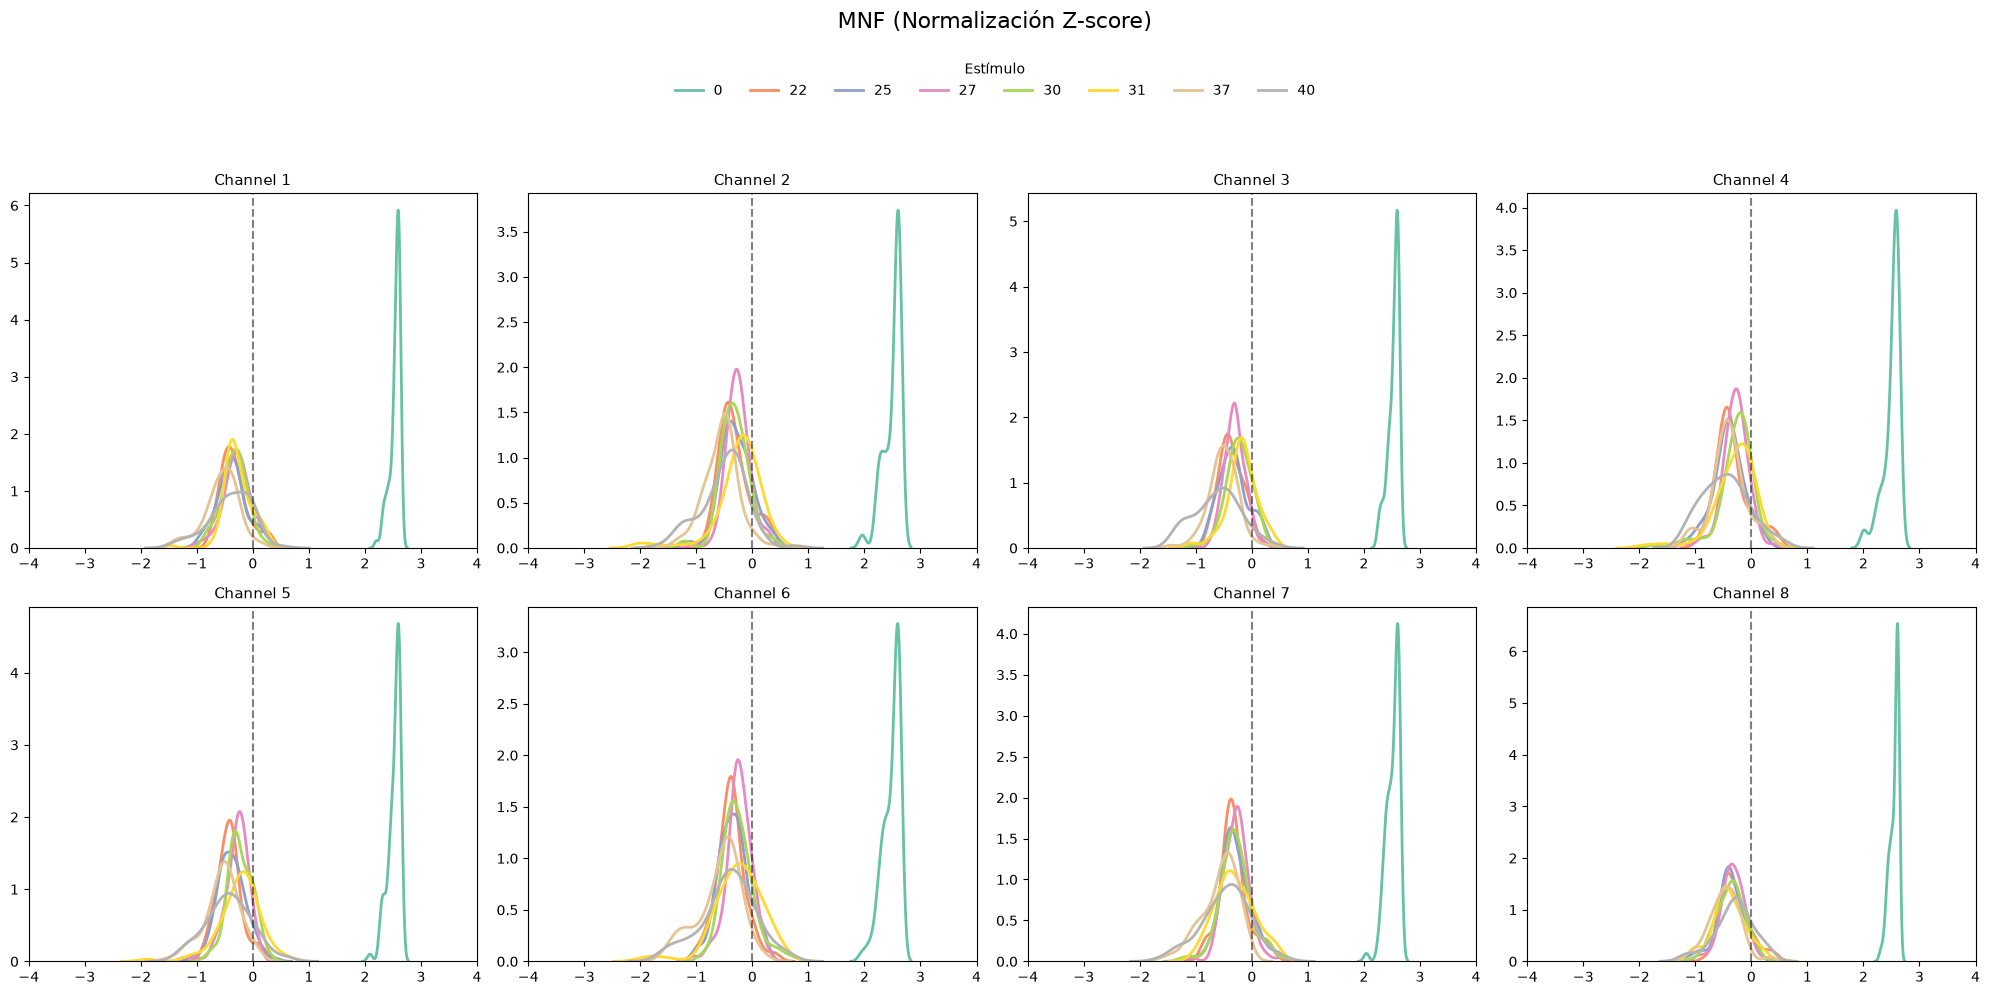

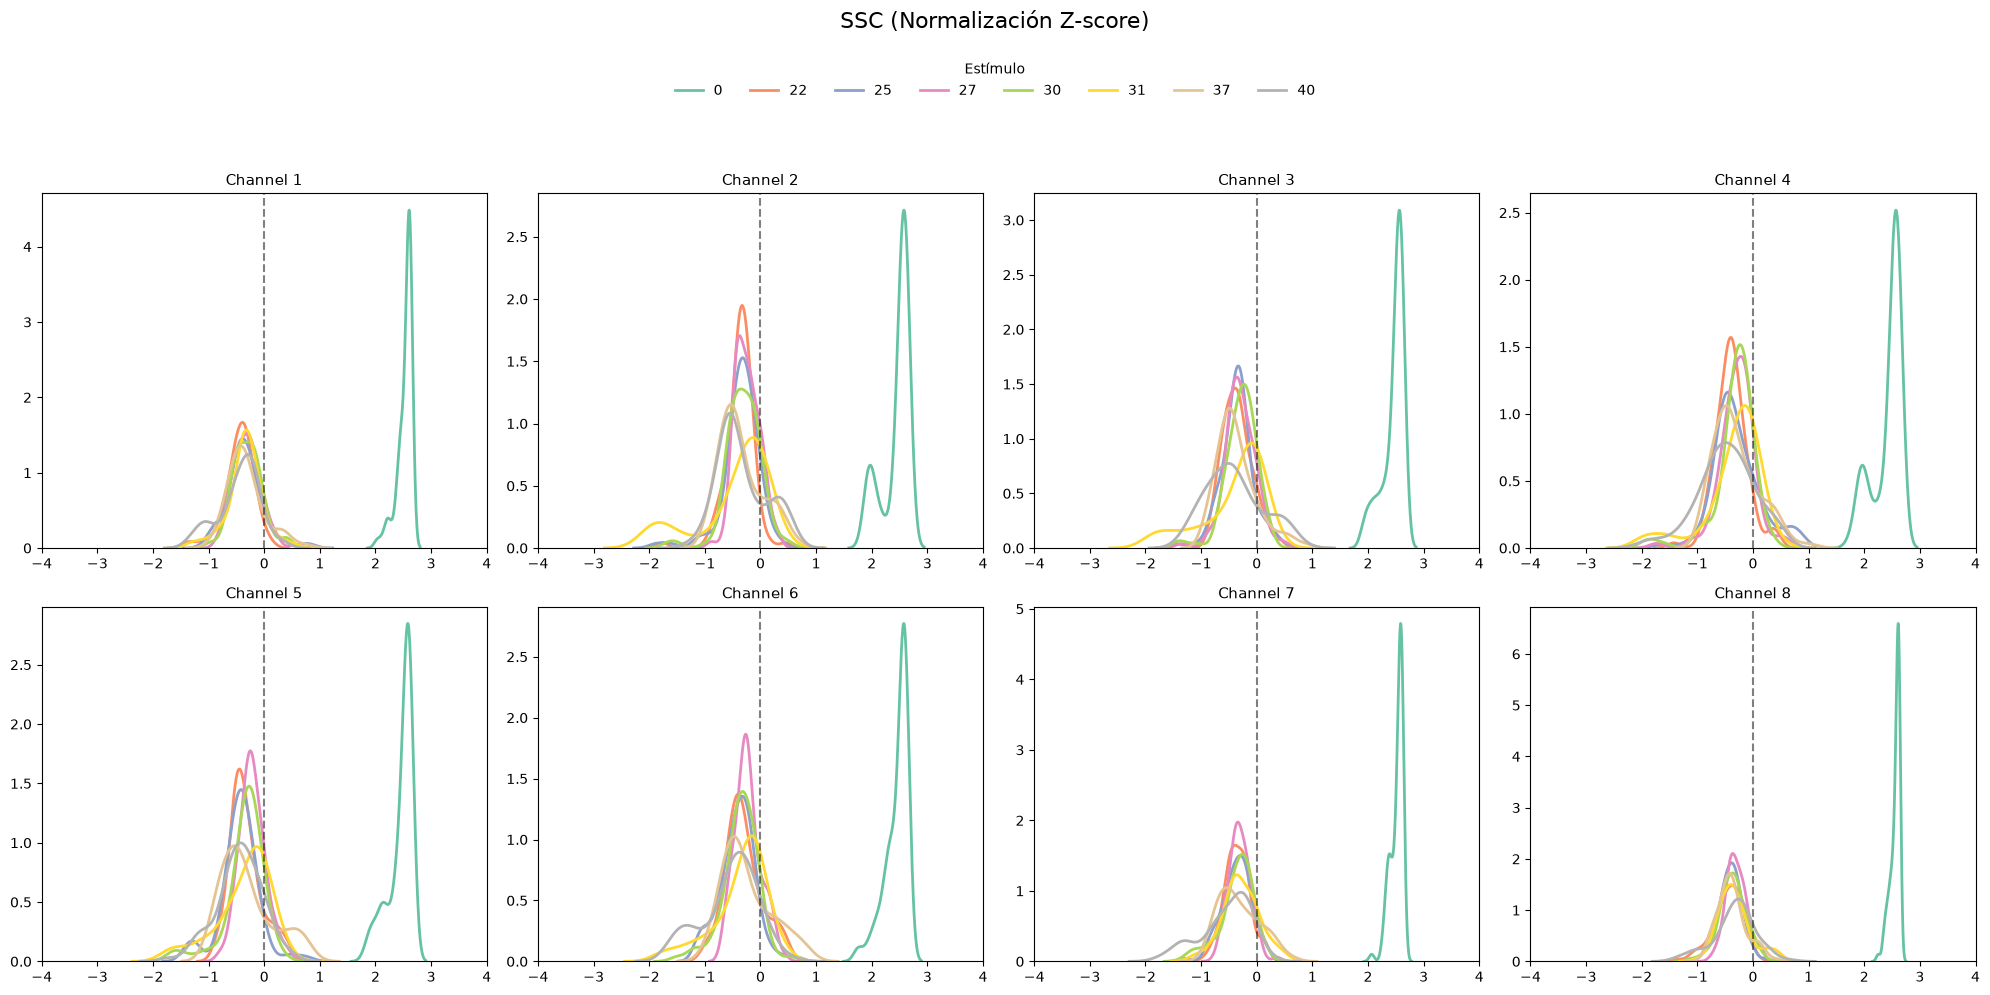

In [15]:
plot_kde_normalized(intact_bc,features)

### Histogramas

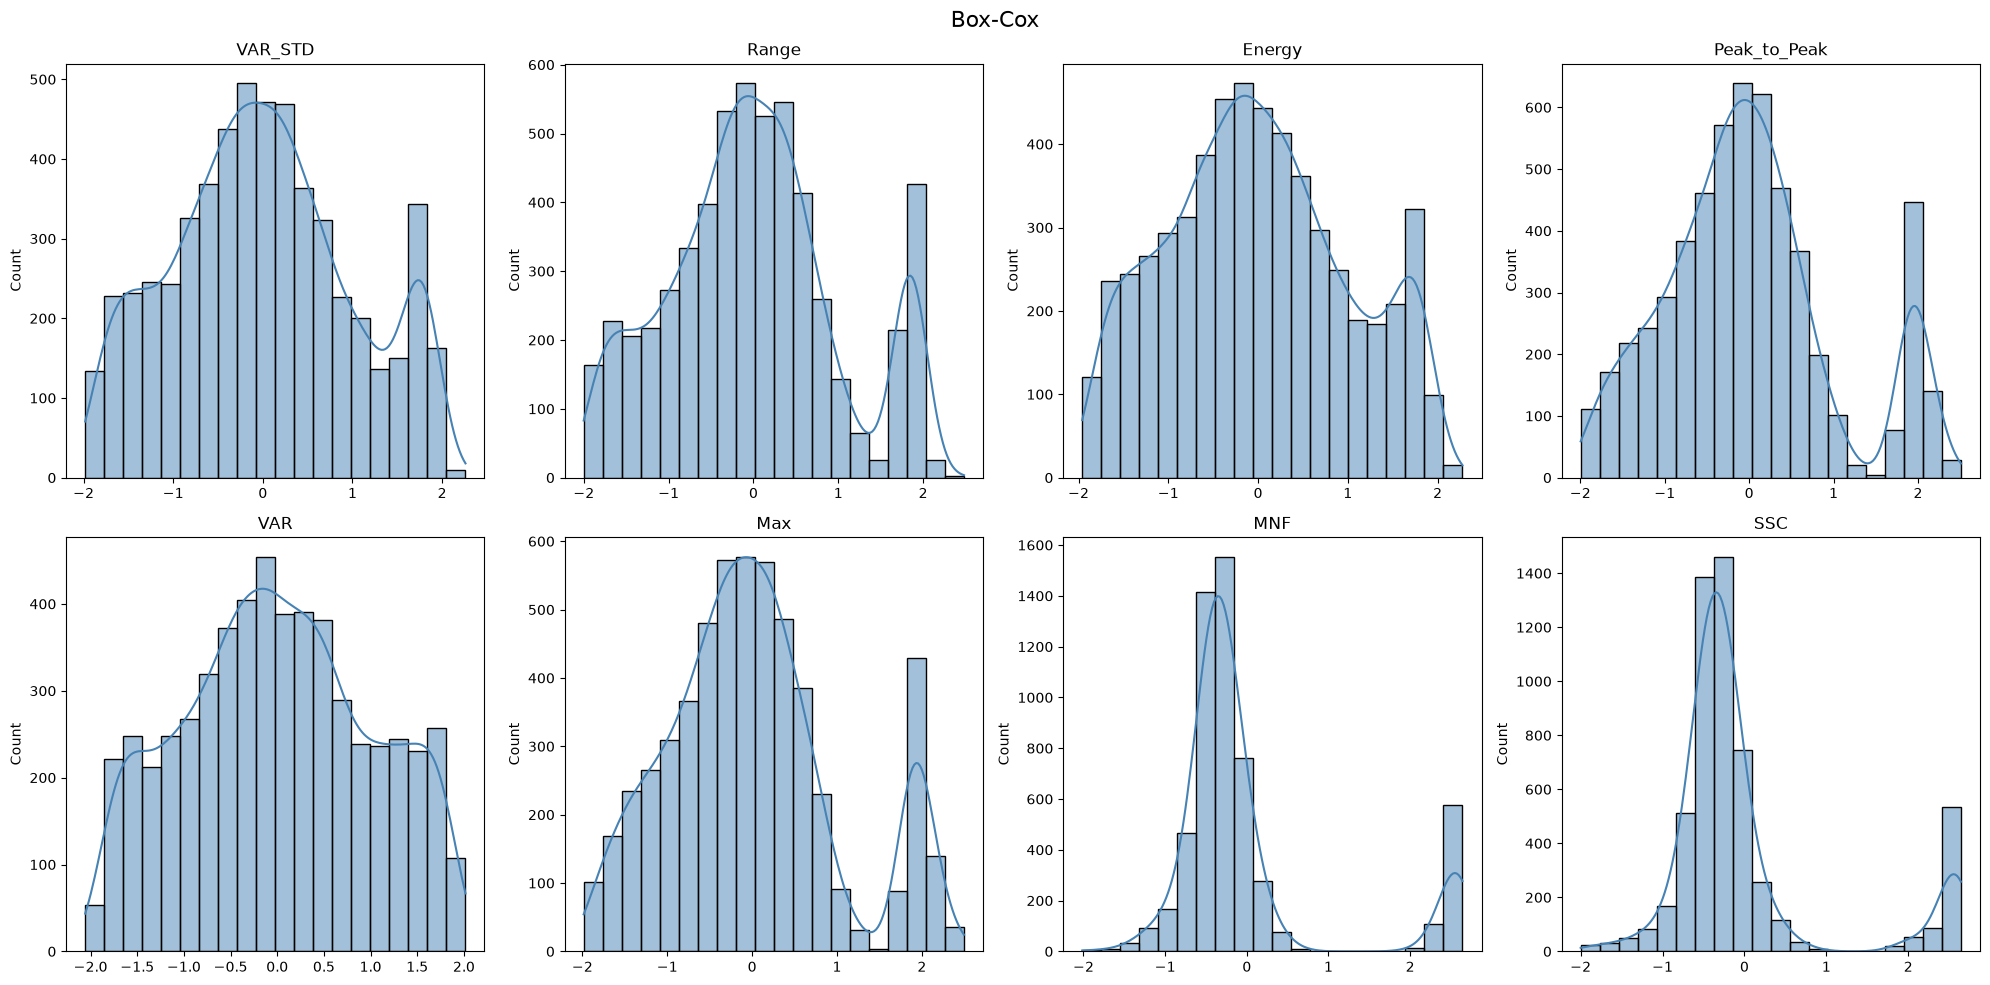

In [16]:
plot_histograms_by_channel(intact_bc,'Box-Cox')

# Comparación

In [17]:
# Calcular métricas de distribución para cada transformación
def distribution_metrics(df, signal_cols):

    results = []

    for col in signal_cols:

        vals = df[col].dropna()

        # Asimetría de la distribución
        skewness = vals.skew()

        # Curtosis de la distribución
        kurtosis = vals.kurt()

        results.append({
            'feature': col,
            'abs_skewness': abs(skewness),
            'abs_kurtosis': abs(kurtosis)
        })

    return pd.DataFrame(results)

# Calcular métricas para cada transformación
metrics_orig = distribution_metrics(intact, signal_cols)
metrics_norm = distribution_metrics(intact_norm, signal_cols)
metrics_yj   = distribution_metrics(intact_yj, signal_cols)
metrics_bc   = distribution_metrics(intact_bc, signal_cols)

- Asimetría (Skewness): Mejor es más cercano a 0.
- Curtosis: Mejor es más cercano a 0.

In [18]:
# Comparación global
comparison = pd.DataFrame({
    'Transformacion': [
        'Original',
        'Z-score',
        'Yeo-Johnson',
        'Box-Cox'
    ],
    'Mean_Abs_Skewness': [
        metrics_orig['abs_skewness'].mean(),
        metrics_norm['abs_skewness'].mean(),
        metrics_yj['abs_skewness'].mean(),
        metrics_bc['abs_skewness'].mean()
    ],
    'Mean_Abs_Kurtosis': [
        metrics_orig['abs_kurtosis'].mean(),
        metrics_norm['abs_kurtosis'].mean(),
        metrics_yj['abs_kurtosis'].mean(),
        metrics_bc['abs_kurtosis'].mean()
    ]
})

print(comparison.round(4))

  Transformacion  Mean_Abs_Skewness  Mean_Abs_Kurtosis
0       Original             8.5716           102.8134
1        Z-score             2.0210             2.5013
2    Yeo-Johnson             1.0727             1.0032
3        Box-Cox             0.6461             0.9545


La aplicación de transformaciones permitió mejorar de forma importante las propiedades distribucionales de las variables respecto a los datos originales. Los datos sin transformar presentaban una elevada asimetría media (8.35) y una curtosis extremadamente alta (102.12), lo que indica distribuciones fuertemente sesgadas y alejadas de un comportamiento aproximadamente normal.

La normalización mediante Z-score por sujeto redujo considerablemente estos efectos, disminuyendo la asimetría media a 1.85 y la curtosis media a 2.10. Esto sugiere que parte de la variabilidad observada inicialmente estaba asociada a diferencias individuales entre sujetos y no exclusivamente a los estímulos evaluados.

Las transformaciones de potencia produjeron una mejora adicional. Tanto Yeo-Johnson como Box-Cox generaron distribuciones más equilibradas y con valores de asimetría y curtosis mucho más cercanos a cero. En términos de asimetría, Box-Cox obtuvo el mejor resultado (0.61), indicando distribuciones más simétricas. Por su parte, Yeo-Johnson presentó la menor curtosis (0.998), aunque la diferencia respecto a Box-Cox (1.066) fue muy pequeña.

Considerando ambas métricas en conjunto, puede concluirse que las dos transformaciones de potencia mejoran notablemente la calidad estadística de los datos. Sin embargo, Box-Cox mostró el mejor desempeño global al producir distribuciones más simétricas y mantener niveles de curtosis muy similares a los obtenidos con Yeo-Johnson. Por esta razón, Box-Cox fue seleccionado como la transformación más adecuada para las etapas posteriores del análisis.

Es importante señalar que esta comparación se centró únicamente en propiedades distribucionales de las variables. La decisión final sobre la transformación más conveniente la complementaremos posteriormente con el rendimiento obtenido en tareas de clasificación o discriminación de estímulos, ya que una distribución más cercana a la normalidad no necesariamente implica una mejor capacidad predictiva.